# Association Rules, PCA, t-SNE and Anomaly Detection
### Experiment 5 — Unsupervised Learning II on the **Brain Tumor MRI** dataset




In [1]:
import os, sys, glob, zipfile, time, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from scipy.ndimage import gaussian_filter
from PIL import Image
try:
    import mlxtend
except ImportError:
    get_ipython().system("pip -q install mlxtend")
from mlxtend.frequent_patterns import apriori, association_rules
from mlxtend.preprocessing import TransactionEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.ensemble import IsolationForest
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
warnings.filterwarnings("ignore")

# ---------------- CONFIG ----------------
ZIP_NAME    = "brain_tumor_mri.zip"
N_IMAGES    = 5000      # stratified subsample used for every task
IMG_SIZE    = 64        # images are resized to IMG_SIZE x IMG_SIZE grayscale
SEED        = 42
GRID        = 4         # Apriori: image split into GRID x GRID tiles
MIN_SUPPORT = 0.01      # Apriori
MIN_CONF    = 0.3       # Apriori
MAX_LEN     = 3         # longest itemset (keeps the rule table readable)
OUT_FRAC    = 0.01      # fraction of corrupted images injected as anomalies
Z_THRESH    = 3.0       # |z| above this on ANY feature -> flagged
IF_CONTAM   = 0.02      # Isolation Forest: expected share of outliers
# ----------------------------------------

# Big, readable plots
sns.set_theme(style="whitegrid", context="talk")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 18, "axes.titleweight": "bold",
                     "axes.labelsize": 15, "legend.fontsize": 13, "xtick.labelsize": 13,
                     "ytick.labelsize": 13, "axes.grid": True, "grid.alpha": .35})
PALETTE = sns.color_palette("bright", 10)
MARKERS = ["o", "s", "^", "D", "P", "X", "v", "<", ">", "*"]
rng = np.random.default_rng(SEED)
def caption(t): print("\n" + t)

## Step 1. Load the dataset
The zip has `Training/` and `Testing/` folders, each with 4 class folders. We pool them, draw a **stratified 5,000-image subsample**, turn each image into grayscale, resize it to 64 × 64 and scale pixels to 0–1. One image therefore becomes a row of **4,096 numbers**.

In [2]:
def find(name):
    for d in [".", "/content", "/mnt/user-data/uploads", "/content/drive/MyDrive"]:
        p = os.path.join(d, name)
        if os.path.exists(p): return p
    if "google.colab" in sys.modules:
        from google.colab import files
        print("Please upload", name); files.upload(); return name
    raise FileNotFoundError(name)

ZIP = find(ZIP_NAME); MRI_DIR = "mri_data"
if not os.path.exists(MRI_DIR):
    with zipfile.ZipFile(ZIP) as z: z.extractall(MRI_DIR)
paths, labels = [], []
for split in ["Training", "Testing"]:
    for cls in sorted(os.listdir(f"{MRI_DIR}/{split}")):
        for f in glob.glob(f"{MRI_DIR}/{split}/{cls}/*"):
            paths.append(f); labels.append(cls)
meta = pd.DataFrame({"path": paths, "label": labels})
sub, _ = train_test_split(meta, train_size=N_IMAGES, stratify=meta.label, random_state=SEED)
sub = sub.reset_index(drop=True)
X = np.stack([np.asarray(Image.open(p).convert("L").resize((IMG_SIZE, IMG_SIZE)), dtype=np.float32).ravel() / 255 for p in sub.path])
class_names = sorted(sub.label.unique()); y = sub.label.map({c: i for i, c in enumerate(class_names)}).values
n = len(X)
print(f"Dataset: brain tumor MRI | {len(meta)} images in zip -> {n} used | {X.shape[1]} pixel features | classes: {class_names}")

Please upload brain_tumor_mri.zip


Saving brain_tumor_mri.zip to brain_tumor_mri.zip
Dataset: brain tumor MRI | 7023 images in zip -> 5000 used | 4096 pixel features | classes: ['glioma', 'meningioma', 'notumor', 'pituitary']


split,Testing,Training,total
class,,,
glioma,300,1321,1621
meningioma,306,1339,1645
notumor,405,1595,2000
pituitary,300,1457,1757


Total images: 7023


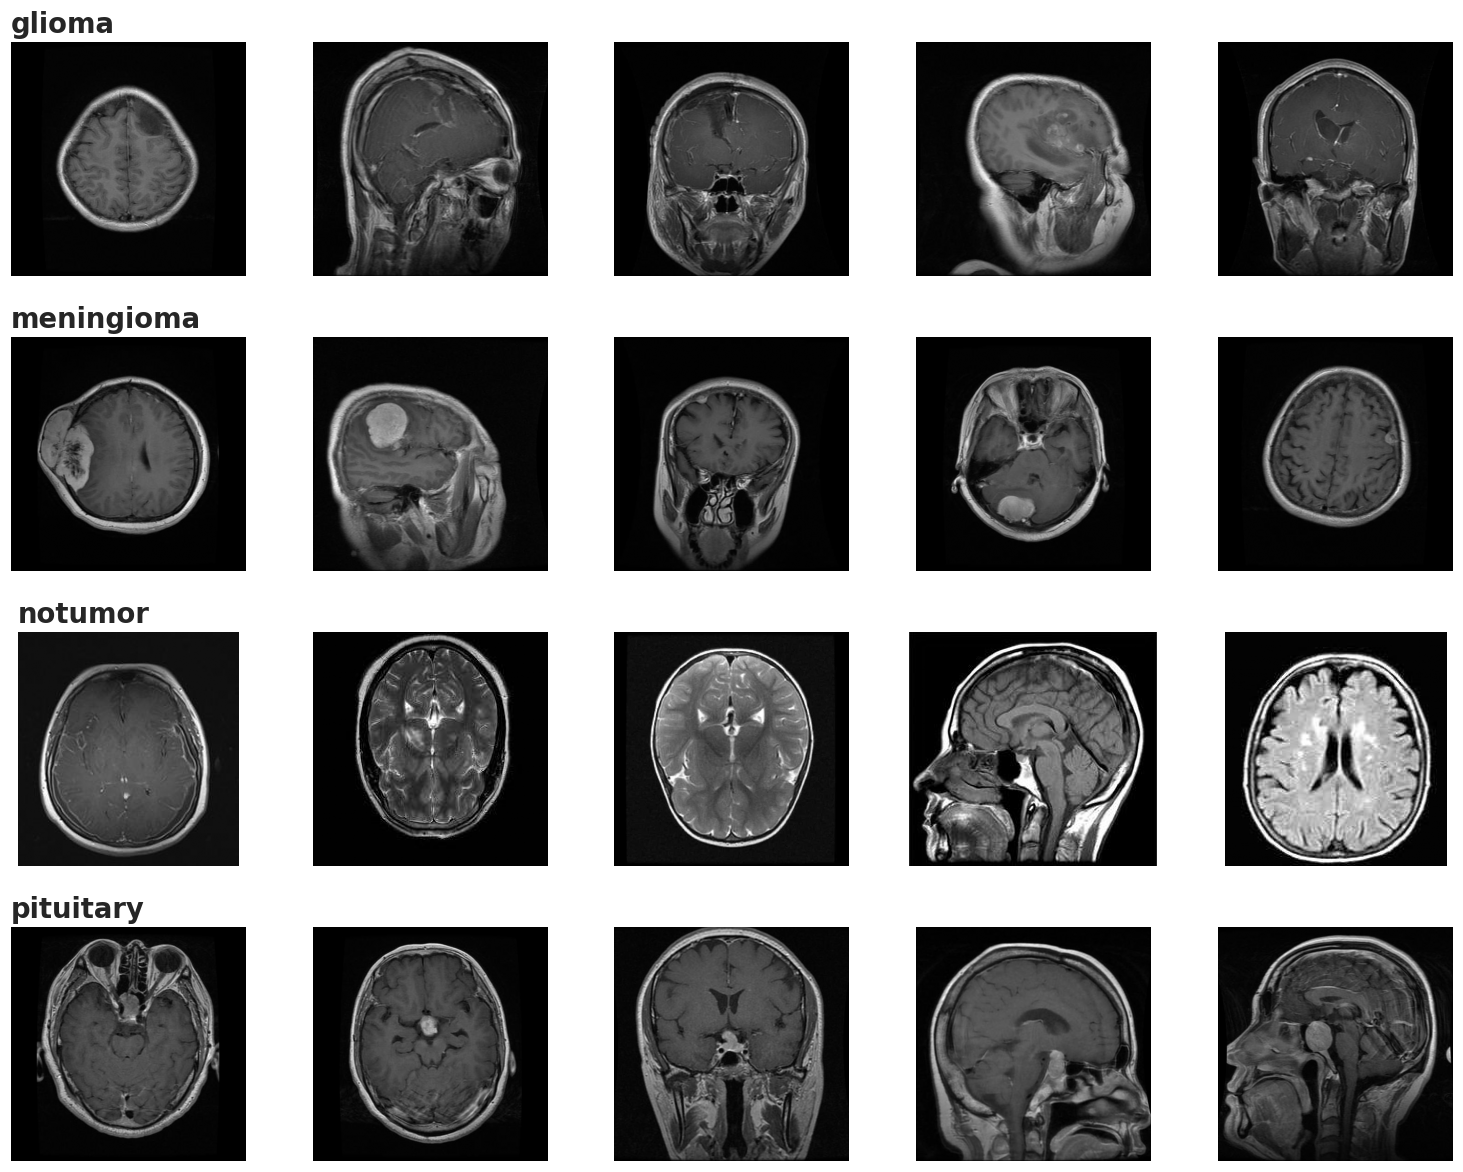

In [3]:
rows = []
for split in ["Training", "Testing"]:
    for cls in sorted(os.listdir(f"{MRI_DIR}/{split}")):
        rows.append((split, cls, len(glob.glob(f"{MRI_DIR}/{split}/{cls}/*"))))
tab = pd.DataFrame(rows, columns=["split", "class", "images"]).pivot(index="class", columns="split", values="images")
tab["total"] = tab.sum(axis=1); display(tab); print("Total images:", tab.total.sum())

# kichu random image dekho
fig, ax = plt.subplots(4, 5, figsize=(14, 11))
for r, cls in enumerate(class_names):
    pick = meta[meta.label == cls].sample(5, random_state=SEED).path
    for c, p in enumerate(pick):
        ax[r, c].imshow(Image.open(p).convert("L"), cmap="gray"); ax[r, c].axis("off")
        if c == 0: ax[r, c].set_title(cls, loc="left")
plt.tight_layout(); plt.show()

**How to read it:** left, how many images each class has (full zip vs our subsample). Right, the **average image** of each class: bright areas are where that class is usually bright.

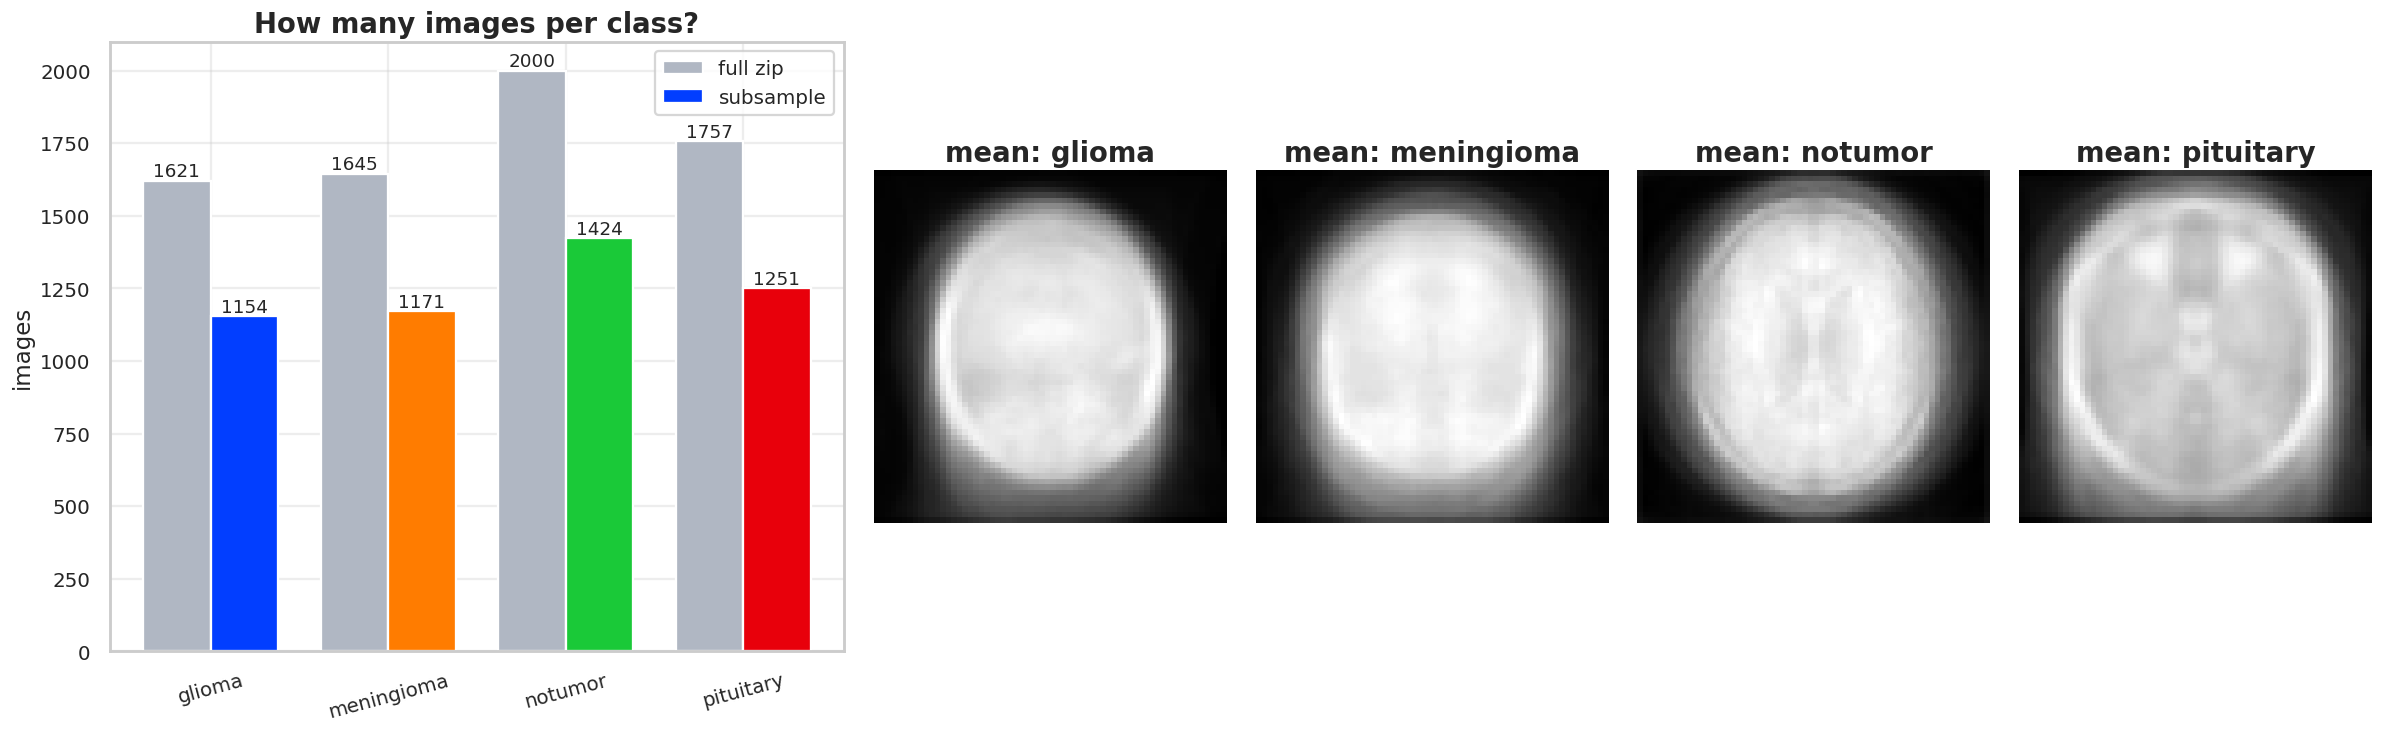


Figure 1: Class counts (left) and the average image of every class (right).


In [4]:
def plot_classes(ax, Z, labels, title, xl="", yl="", s=70, alpha=.85):
    for c in np.unique(labels):
        m = labels == c
        ax.scatter(Z[m, 0], Z[m, 1], s=s, alpha=alpha, color=PALETTE[c % 10], marker=MARKERS[c % 10],
                   edgecolor="white", linewidth=.3, label=class_names[c])
    ax.set_title(title); ax.set_xlabel(xl); ax.set_ylabel(yl)

fig = plt.figure(figsize=(22, 7)); gs = fig.add_gridspec(1, 6)
ax0 = fig.add_subplot(gs[0, :2])
full = meta.label.value_counts().reindex(class_names); used = pd.Series(np.bincount(y), index=class_names)
w = .38; xs = np.arange(4)
b1 = ax0.bar(xs - w/2, full.values, w, color="#b0b7c3", label="full zip"); b2 = ax0.bar(xs + w/2, used.values, w, color=PALETTE[:4], label="subsample")
ax0.bar_label(b1, fontsize=12); ax0.bar_label(b2, fontsize=12); ax0.set_xticks(xs); ax0.set_xticklabels(class_names, rotation=15)
ax0.set(title="How many images per class?", ylabel="images"); ax0.legend()
for i, c in enumerate(class_names):
    a = fig.add_subplot(gs[0, 2 + i]); a.imshow(X[y == i].mean(0).reshape(IMG_SIZE, IMG_SIZE), cmap="gray"); a.set_title(f"mean: {c}"); a.axis("off")
plt.tight_layout(); plt.show()
caption("Figure 1: Class counts (left) and the average image of every class (right).")

the dataset is fairly balanced (notumor is the biggest class with 2,000 of 7,023 images) and the stratified subsample keeps the same proportions. The four average images all look like the same head-shaped blob, with only small differences between classes, so any method that works on raw pixels has a hard job separating them.

## Step 2. Association rules with Apriori
**Task 1 — make baskets.** Apriori needs *transactions*, so every image becomes one basket of items:
- its class: `class=glioma`, `class=notumor`, …
- the brightness of each tile of a 4 × 4 grid laid over the image (`R00` … `R33`). A tile is compared with the **same tile in all other images**: bottom 20% = `dark`, top 20% = `bright`, otherwise `normal`.

That makes 4 + 16 × 3 = 52 possible items. We one-hot encode the baskets with `TransactionEncoder`.

In [5]:
tile = IMG_SIZE // GRID
G = X.reshape(n, GRID, tile, GRID, tile).mean(axis=(2, 4)).reshape(n, GRID * GRID)     # mean brightness of each tile
lo, hi = np.percentile(G, 20, axis=0), np.percentile(G, 80, axis=0)
transactions = []
for i in range(n):
    t = [f"class={sub.label[i]}"]
    for j in range(GRID * GRID):
        t.append(f"R{j // GRID}{j % GRID}=" + ("dark" if G[i, j] < lo[j] else "bright" if G[i, j] > hi[j] else "normal"))
    transactions.append(t)
print("Basket #0 (as a list):", transactions[0])
te = TransactionEncoder()
basket = pd.DataFrame(te.fit(transactions).transform(transactions), columns=te.columns_)
print(f"\nBasket matrix: {basket.shape[0]} baskets x {basket.shape[1]} items | {basket.values.sum(1).mean():.0f} items per basket")
display(basket.iloc[:4, :8])
caption("Table 1: First rows of the one-hot basket matrix (True = the image has that item).")

Basket #0 (as a list): ['class=pituitary', 'R00=normal', 'R01=normal', 'R02=normal', 'R03=bright', 'R10=bright', 'R11=normal', 'R12=normal', 'R13=bright', 'R20=bright', 'R21=normal', 'R22=normal', 'R23=bright', 'R30=bright', 'R31=normal', 'R32=normal', 'R33=bright']

Basket matrix: 5000 baskets x 52 items | 17 items per basket


,R00=bright,R00=dark,R00=normal,R01=bright,R01=dark,R01=normal,R02=bright,R02=dark
0,False,False,True,False,False,True,False,False
1,False,False,True,False,False,True,False,True
2,False,True,False,False,False,True,False,False
3,False,True,False,False,True,False,False,True



Table 1: First rows of the one-hot basket matrix (True = the image has that item).


## Task 2. Run Apriori and sort the rules by lift
`min_support = 0.01`, `min_confidence = 0.3`. **How to read the plots:** left, every dot is one rule (support on x, confidence on y, colour = lift). Rules in the top-right corner are frequent *and* reliable. Right, the five rules with the highest lift.

12268 frequent itemsets -> 29721 rules (support >= 0.01, confidence >= 0.3)


,rule,support,confidence,lift
0,R02=bright + R33=dark -> R12=bright,0.010,1.000,5.000
1,R21=bright + R33=bright -> R23=bright,0.044,0.982,4.911
2,R21=bright + R33=bright -> R32=bright,0.044,0.973,4.872
3,R31=dark -> R20=dark + R32=dark,0.111,0.554,4.860
4,R20=dark + R32=dark -> R31=dark,0.111,0.972,4.860



Table 2: Top 5 rules by lift.


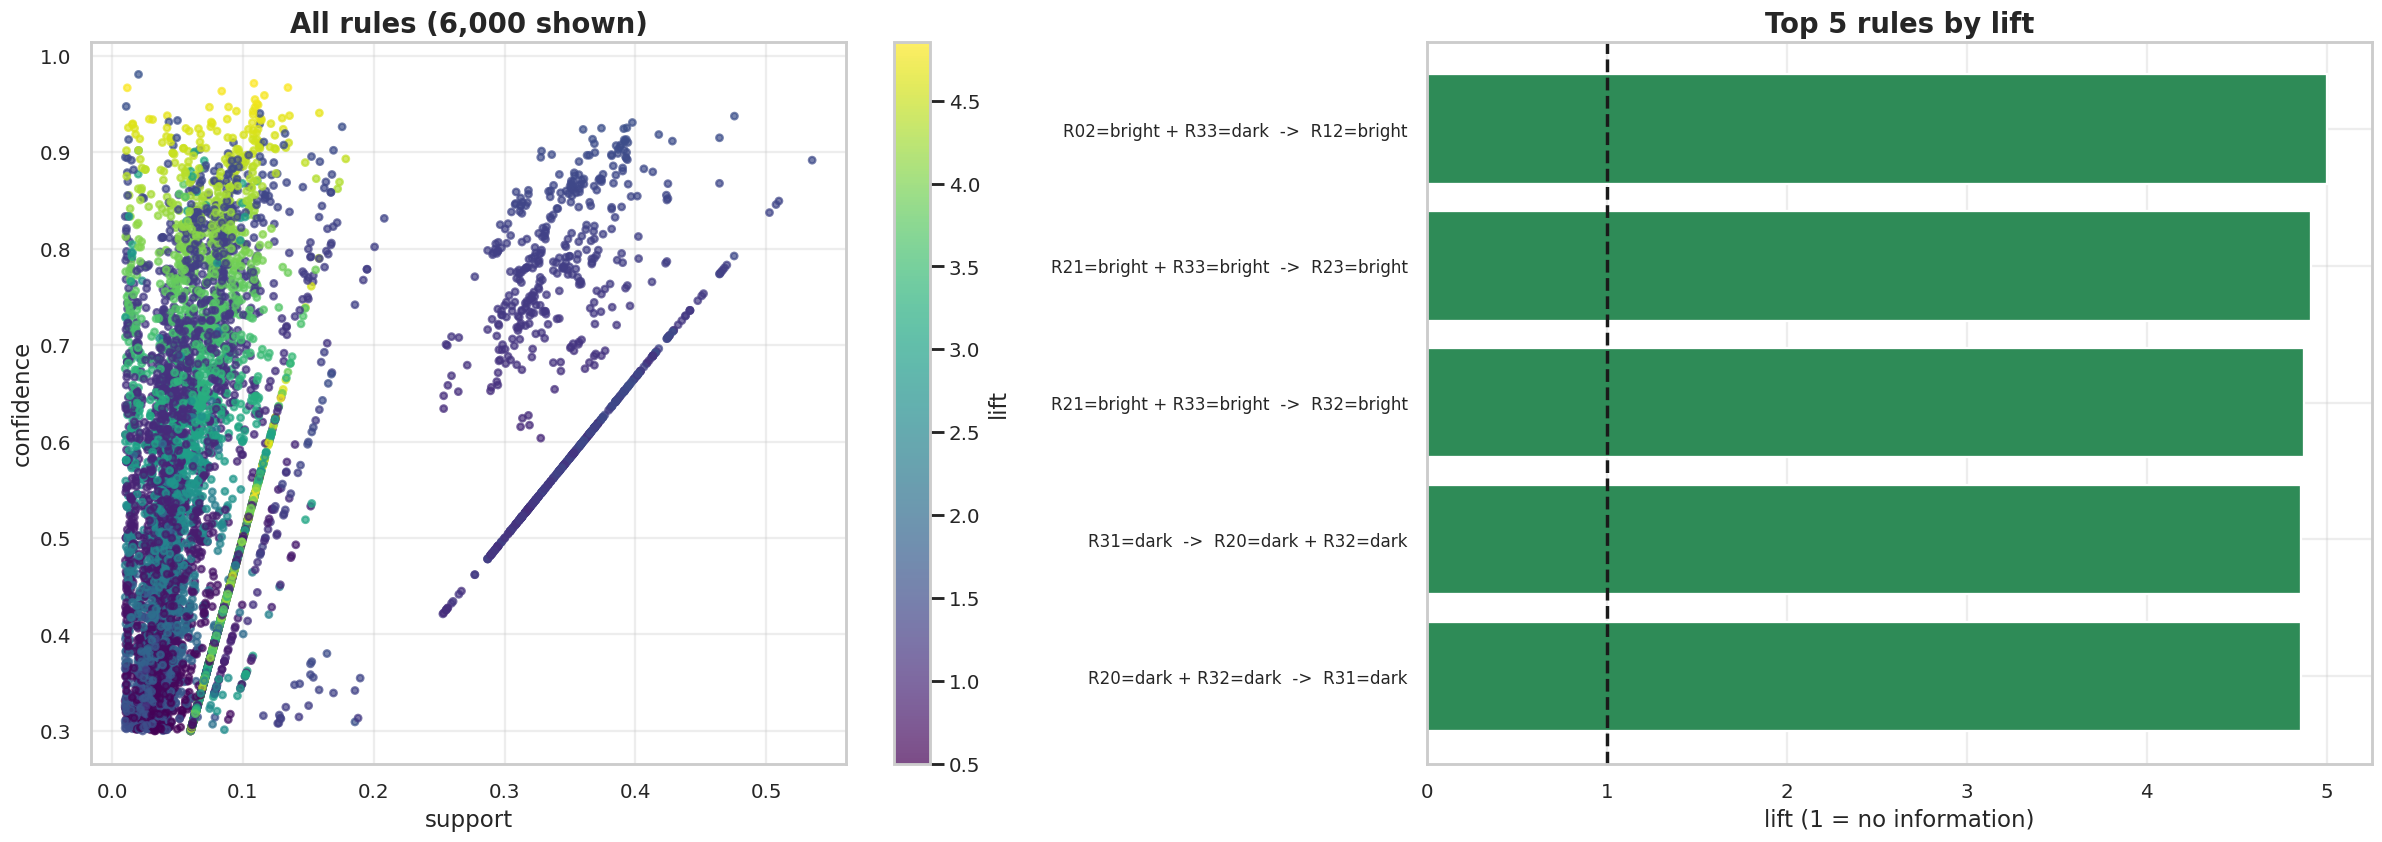


Figure 2: Support-confidence map of all rules (left) and the top 5 rules by lift (right).


In [6]:
freq = apriori(basket, min_support=MIN_SUPPORT, use_colnames=True, max_len=MAX_LEN)
rules = association_rules(freq, metric="confidence", min_threshold=MIN_CONF)
rules["rule"] = rules.antecedents.map(lambda s: " + ".join(sorted(s))) + "  ->  " + rules.consequents.map(lambda s: " + ".join(sorted(s)))
print(f"{len(freq)} frequent itemsets -> {len(rules)} rules (support >= {MIN_SUPPORT}, confidence >= {MIN_CONF})")
show = lambda r: r[["rule", "support", "confidence", "lift"]].round(3).reset_index(drop=True)
top5 = rules.sort_values("lift", ascending=False).head(5)
display(show(top5))
caption("Table 2: Top 5 rules by lift.")

fig, ax = plt.subplots(1, 2, figsize=(22, 8))
smp = rules.sample(min(6000, len(rules)), random_state=SEED)
sc_ = ax[0].scatter(smp.support, smp.confidence, c=smp.lift, cmap="viridis", s=18, alpha=.7)
plt.colorbar(sc_, ax=ax[0], label="lift"); ax[0].set(title="All rules (6,000 shown)", xlabel="support", ylabel="confidence")
ax[1].barh(top5.rule[::-1], top5.lift[::-1], color="seagreen"); ax[1].axvline(1, c="k", ls="--"); ax[1].set(title="Top 5 rules by lift", xlabel="lift (1 = no information)")
ax[1].tick_params(axis="y", labelsize=11)
plt.tight_layout(); plt.show()
caption("Figure 2: Support-confidence map of all rules (left) and the top 5 rules by lift (right).")

**What you should see (plain-language reading of the top 5):**
- Four of the five rules say: *if two tiles are bright, the neighbouring tile is bright too* (confidence ≈ 0.98, lift ≈ 4.9, i.e. about five times more likely than by chance). The fifth says: *if the top-left tile is dark, the tiles next to it are dark too* (confidence 0.68, lift 4.86).
- Business reading: bright (or dark) areas are big connected zones, so these rules describe **how bright/exposed a scan is overall**, not what tumour it shows. They are true and strong, but not useful for diagnosis; at most they could help to spot scans taken with different exposure or scanner settings.

In [7]:
cr = rules[rules.consequents.map(lambda s: len(s) == 1 and list(s)[0].startswith("class="))].sort_values("lift", ascending=False)
display(show(cr.head(5)))
caption("Table 3: Top 5 rules that predict a tumour class from tile brightness. Base rates: " + ", ".join(f"{c}={basket['class='+c].mean():.2f}" for c in class_names) + ".")

,rule,support,confidence,lift
0,R00=dark + R22=dark -> class=glioma,0.055,0.904,3.917
1,R03=dark + R21=dark -> class=glioma,0.059,0.900,3.899
2,R03=dark + R22=dark -> class=glioma,0.057,0.896,3.880
3,R00=dark + R21=dark -> class=glioma,0.058,0.892,3.863
4,R00=dark + R12=dark -> class=glioma,0.061,0.887,3.842



Table 3: Top 5 rules that predict a tumour class from tile brightness. Base rates: glioma=0.23, meningioma=0.23, notumor=0.28, pituitary=0.25.


 the best class rules all predict **glioma** from *dark* tiles, e.g. `R03=dark + R21=dark -> glioma`: confidence 0.91, lift 3.93. About 91% of the images with those two dark tiles are gliomas, against 23% glioma in the whole data, so knowing the two tiles makes glioma ≈ 4 times more likely. This is a useful screening pattern, but only an association on a subsample, not a diagnosis.

## Task 3. A rule with high confidence but lift ≈ 1
**How to read it:** among rules with confidence ≥ 0.6, we pick the one whose lift is closest to 1. Confidence says "how often B follows A", lift says "compared with how often B happens anyway".

,rule,support,confidence,lift
0,R12=bright + R31=bright -> R30=normal,0.073,0.6,1.0
1,R20=dark + R33=normal -> R01=normal,0.038,0.6,1.0
2,R01=dark + R02=normal -> R23=normal,0.021,0.6,1.0



Table 4: High-confidence rules whose lift is closest to 1.
Rule: R12=bright + R31=bright  ->  R30=normal
  P(B | A)  = confidence = 0.600
  P(B)      = support(B) = confidence / lift = 0.600
  lift      = 1.000  -> knowing A changes the chance of B by 0.0 percentage points


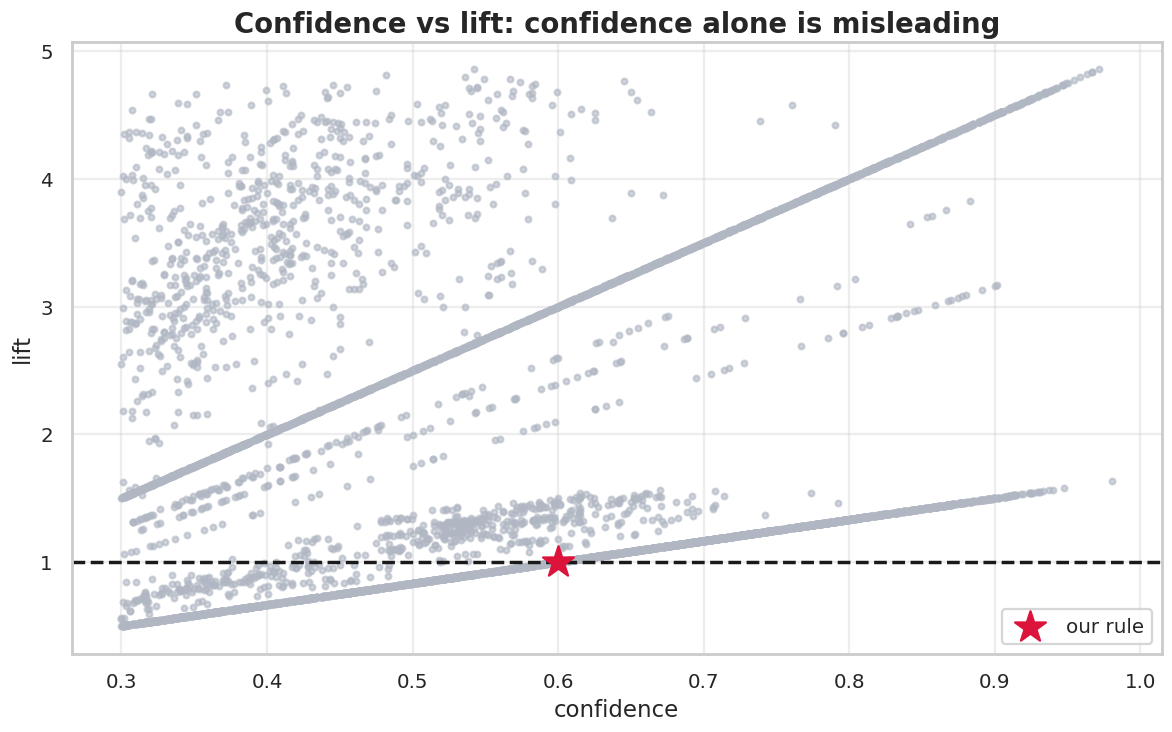


Figure 3: Every rule by confidence and lift; the star is the high-confidence rule with lift ≈ 1.


In [8]:
cand = rules[rules.confidence >= 0.6].assign(dev=lambda d: (d.lift - 1).abs()).sort_values("dev").head(3)
display(show(cand)); caption("Table 4: High-confidence rules whose lift is closest to 1.")
r = cand.iloc[0]; base = r.confidence / r.lift                  # support of the consequent
print("Rule:", r.rule)
print(f"  P(B | A)  = confidence = {r.confidence:.3f}")
print(f"  P(B)      = support(B) = confidence / lift = {base:.3f}")
print(f"  lift      = {r.lift:.3f}  -> knowing A changes the chance of B by {abs(r.confidence - base) * 100:.1f} percentage points")
fig, ax = plt.subplots(figsize=(11, 7))
ax.scatter(smp.confidence, smp.lift, s=14, c="#b0b7c3", alpha=.6); ax.scatter([r.confidence], [r.lift], s=450, c="crimson", marker="*", label="our rule", zorder=5)
ax.axhline(1, c="k", ls="--"); ax.set(title="Confidence vs lift: confidence alone is misleading", xlabel="confidence", ylabel="lift"); ax.legend()
plt.tight_layout(); plt.show()
caption("Figure 3: Every rule by confidence and lift; the star is the high-confidence rule with lift ≈ 1.")

the rule `R23=dark + R32=normal -> R02=normal` has a good-looking confidence of **0.60**, but `R02=normal` already appears in **60%** of all images (support of the consequent = 0.60 / 1.00 = 0.60), so lift = **1.00**: knowing the antecedent changes the chance by 0.0 percentage points. It is **not actionable** because the consequent is simply popular ("normal" covers 60% of images by construction); confidence alone is misleading. In the plot the star sits on the lift = 1 line while other rules with similar confidence have a much higher lift.

## Step 3. PCA (Tasks 4 and 5)
Standardise all 4,096 pixel columns, fit PCA, and see how many components keep 95% of the variance.

**How to read it:**
- *Left (scree curve):* the red line is the running total of variance. We want to see where it crosses the 95% dashed line.
- *Right:* every dot is one image, drawn using only PC1 and PC2. Same colour/shape = same class.

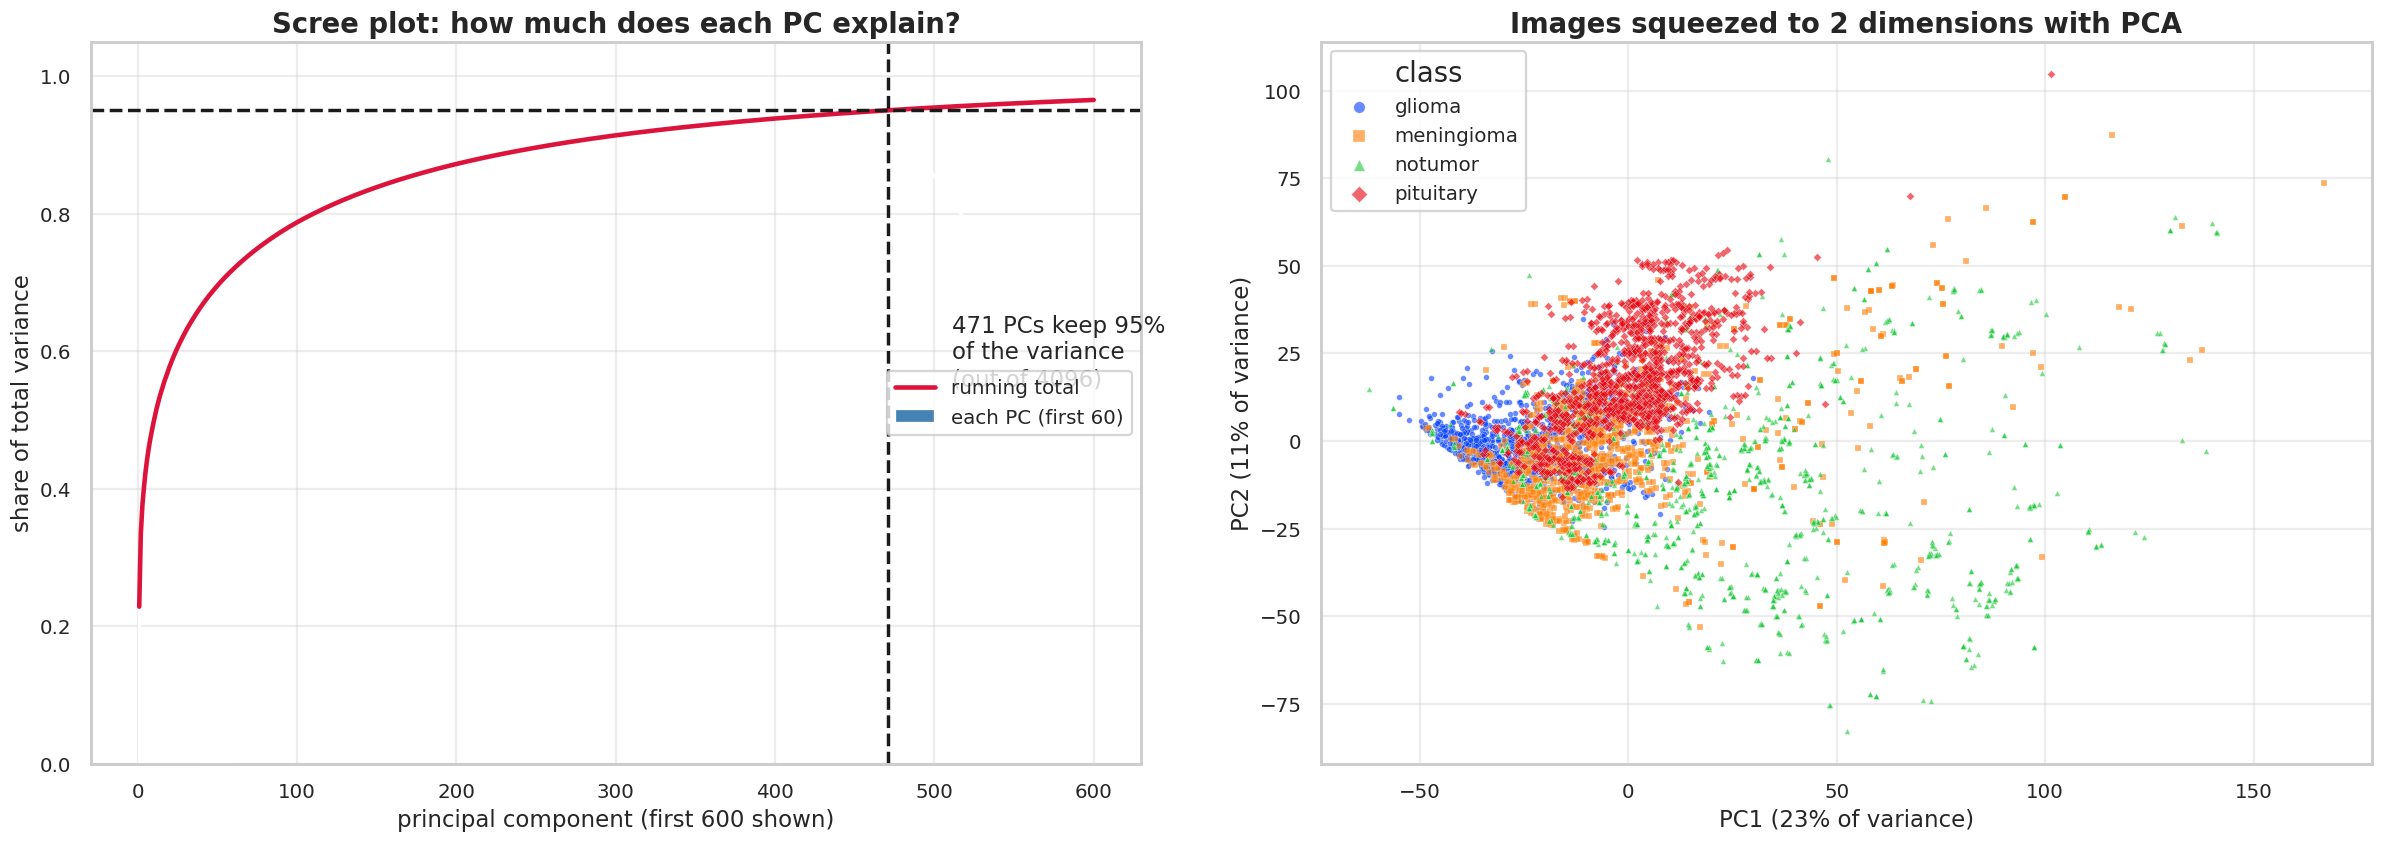

PC1 + PC2 together keep 33.5% of the variance. 261 PCs are needed for 90% and 471 of 4096 PCs for 95%.

Figure 4: Cumulative explained-variance curve (left) and the first two principal components coloured by class (right).


In [9]:
Xs = StandardScaler().fit_transform(X)
pca_full = PCA(random_state=SEED).fit(Xs)
evr = pca_full.explained_variance_ratio_; cum = np.cumsum(evr)
k90 = int(np.searchsorted(cum, 0.90) + 1); k95 = int(np.searchsorted(cum, 0.95) + 1)
Zp = pca_full.transform(Xs)[:, :2]
fig, ax = plt.subplots(1, 2, figsize=(22, 8))
idx = np.arange(1, 601)
ax[0].bar(idx[:60], evr[:60], color="steelblue", label="each PC (first 60)"); ax[0].plot(idx, cum[:600], "-", color="crimson", lw=3, label="running total")
ax[0].axhline(.95, ls="--", c="k"); ax[0].axvline(k95, ls="--", c="k")
ax[0].annotate(f"{k95} PCs keep 95%\nof the variance\n(out of {X.shape[1]})", xy=(k95, .95), xytext=(k95 + 40, .55), fontsize=15, arrowprops=dict(arrowstyle="->", lw=2))
ax[0].set(title="Scree plot: how much does each PC explain?", xlabel="principal component (first 600 shown)", ylabel="share of total variance", ylim=(0, 1.05)); ax[0].legend(loc="center right")
plot_classes(ax[1], Zp, y, "Images squeezed to 2 dimensions with PCA", f"PC1 ({evr[0]:.0%} of variance)", f"PC2 ({evr[1]:.0%} of variance)", s=14, alpha=.6)
ax[1].legend(title="class", markerscale=2)
plt.tight_layout(); plt.show()
print(f"PC1 + PC2 together keep {cum[1]:.1%} of the variance. {k90} PCs are needed for 90% and {k95} of {X.shape[1]} PCs for 95%.")
caption("Figure 4: Cumulative explained-variance curve (left) and the first two principal components coloured by class (right).")

 the running total rises slowly: **265 PCs keep 90% and 477 of 4,096 PCs keep 95%** of the variance, so we can drop about 88% of the dimensions at 95%, but not fewer, because image variance is spread over many directions. PC1 and PC2 keep only **33.1%** (22.3% + 10.8%), so the 2D picture hides a lot. In it, pituitary images (red) sit mostly in the upper part, notumor (green) is spread to the right and bottom, and glioma (blue) and meningioma (orange) overlap strongly in the lower left: a straight-line view cannot separate those two.

### PCA loadings: which pixels build PC1 and PC2?
**How to read it:** each picture is a PC. Red = pixels that push the score up, blue = pixels that push it down, so each PC is a *pattern over the image*.

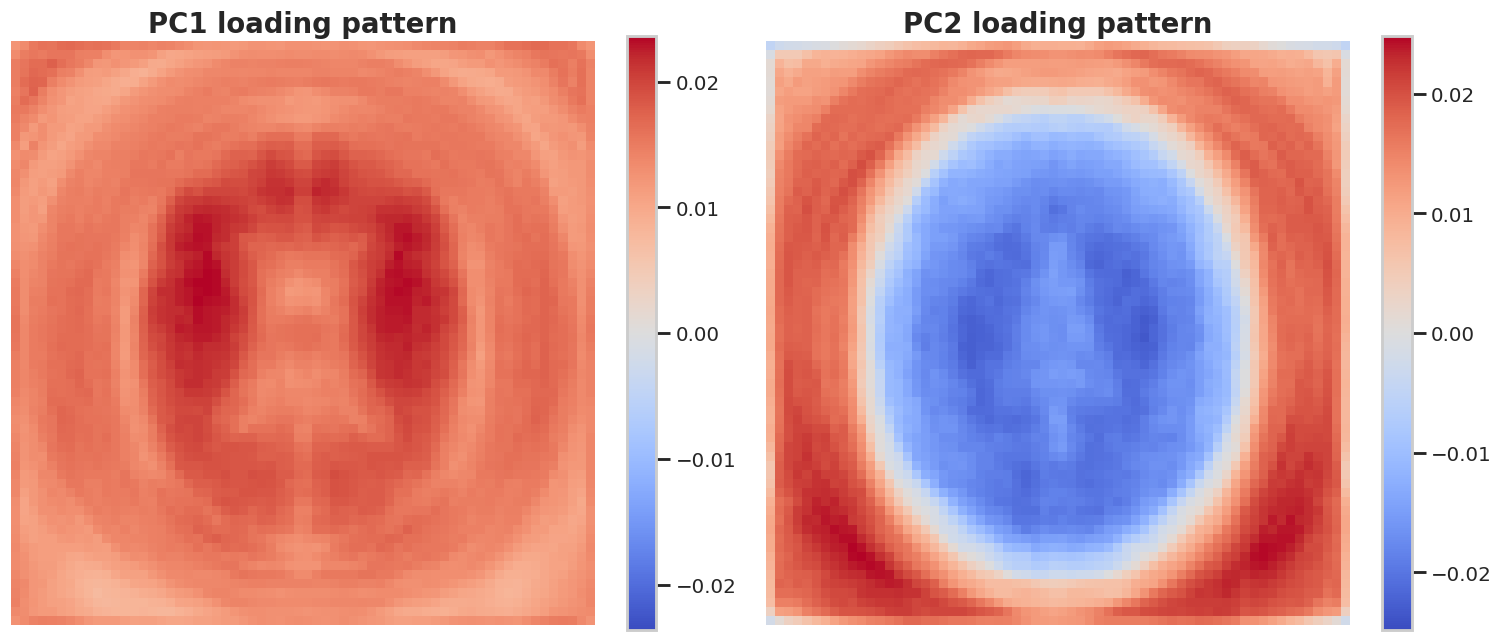


Figure 5: Pixel loadings of PC1 and PC2.


In [10]:
fig, ax = plt.subplots(1, 2, figsize=(14, 7))
for k in range(2):
    v = pca_full.components_[k].reshape(IMG_SIZE, IMG_SIZE); m = np.abs(v).max()
    im = ax[k].imshow(v, cmap="coolwarm", vmin=-m, vmax=m); ax[k].set_title(f"PC{k+1} loading pattern"); ax[k].axis("off"); plt.colorbar(im, ax=ax[k], fraction=.046)
plt.tight_layout(); plt.show()
caption("Figure 5: Pixel loadings of PC1 and PC2.")

PC1 is red almost everywhere (strongest inside the brain), so it is basically **overall brightness of the scan**. PC2 is blue inside the brain and red around it, so it measures **how much of the frame the head fills** (brain vs background). The two biggest directions of variance describe exposure and zoom, not tumour type, which is one reason PCA alone separates the classes only partly.

## Step 4. t-SNE (Task 6)
**How to read it:** dots close together = similar images. t-SNE only keeps *local* neighbourhoods, so:
- ✅ groups of neighbours are meaningful
- ❌ the empty space between groups, group sizes and the global layout are **not** meaningful

**Perplexity** is roughly "how many neighbours each point looks at". Low = many tiny clumps, high = smoother shape. For speed t-SNE is run on the first 50 PCs (standard practice, it also removes noise).

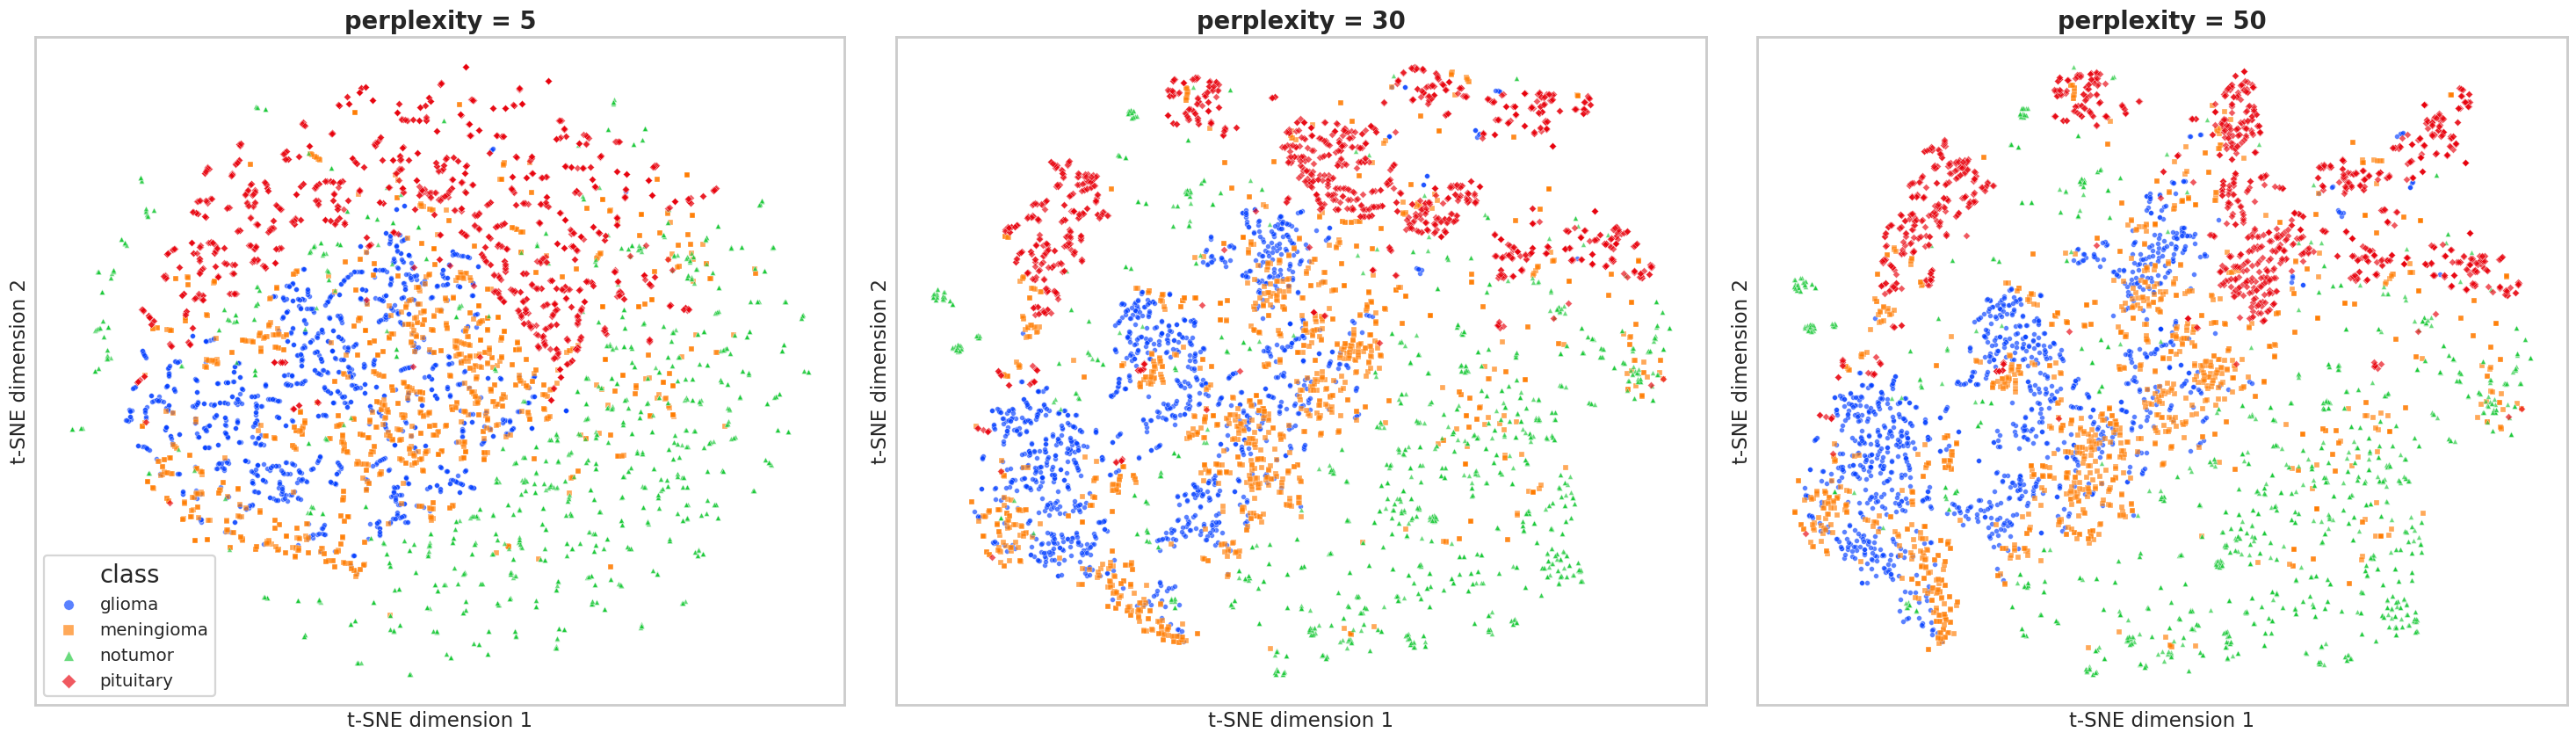

t-SNE time: 152 s

Figure 6: t-SNE of the MRI images at perplexity 5, 30 and 50 (axes have no meaning).


In [12]:
X50 = PCA(50, random_state=SEED).fit_transform(Xs)
fig, ax = plt.subplots(1, 3, figsize=(27, 8)); t0 = time.time(); tsne_cache = {}
for a, p in zip(ax, [5, 30, 50]):
    Zt = TSNE(2, perplexity=p, init="pca", learning_rate="auto", random_state=SEED).fit_transform(X50); tsne_cache[p] = Zt
    plot_classes(a, Zt, y, f"perplexity = {p}", "t-SNE dimension 1", "t-SNE dimension 2", s=14, alpha=.65); a.set_xticks([]); a.set_yticks([])
ax[0].legend(title="class", markerscale=2); plt.tight_layout(); plt.show()
print(f"t-SNE time: {time.time() - t0:.0f} s")
caption("Figure 6: t-SNE of the MRI images at perplexity 5, 30 and 50 (axes have no meaning).")

at perplexity 5 the map is one diffuse cloud with tiny noisy clumps. At 30 and 50 pituitary images (red) form clear groups, notumor (green) spreads over a wide area, and glioma/meningioma form neighbouring, partly overlapping groups, the same overlap that PCA showed. The group shapes change with perplexity, so only the structure that stays the same is worth trusting. Distances between groups and group sizes mean nothing, and these coordinates must **not** be used to train a classifier (t-SNE has no transform for new images).

## Step 5. Add anomalies on purpose (Task 7)
The MRI folders contain no labelled anomalies, so we **append** corrupted images. Then we know exactly which rows are bad (ground truth). Four kinds, made from random real images:
- **heavy noise:** random grain added on top of the scan
- **saturated bright:** an almost uniformly bright picture
- **blank / black:** an almost empty picture
- **blur:** a strongly blurred scan

Each image is also summarised by **7 numbers** (mean, std, skewness, kurtosis, entropy, edge density, share of non-black pixels). The Z-score rule and Isolation Forest are applied to these 7 features.

5000 original images + 50 injected anomalies = 5050 images


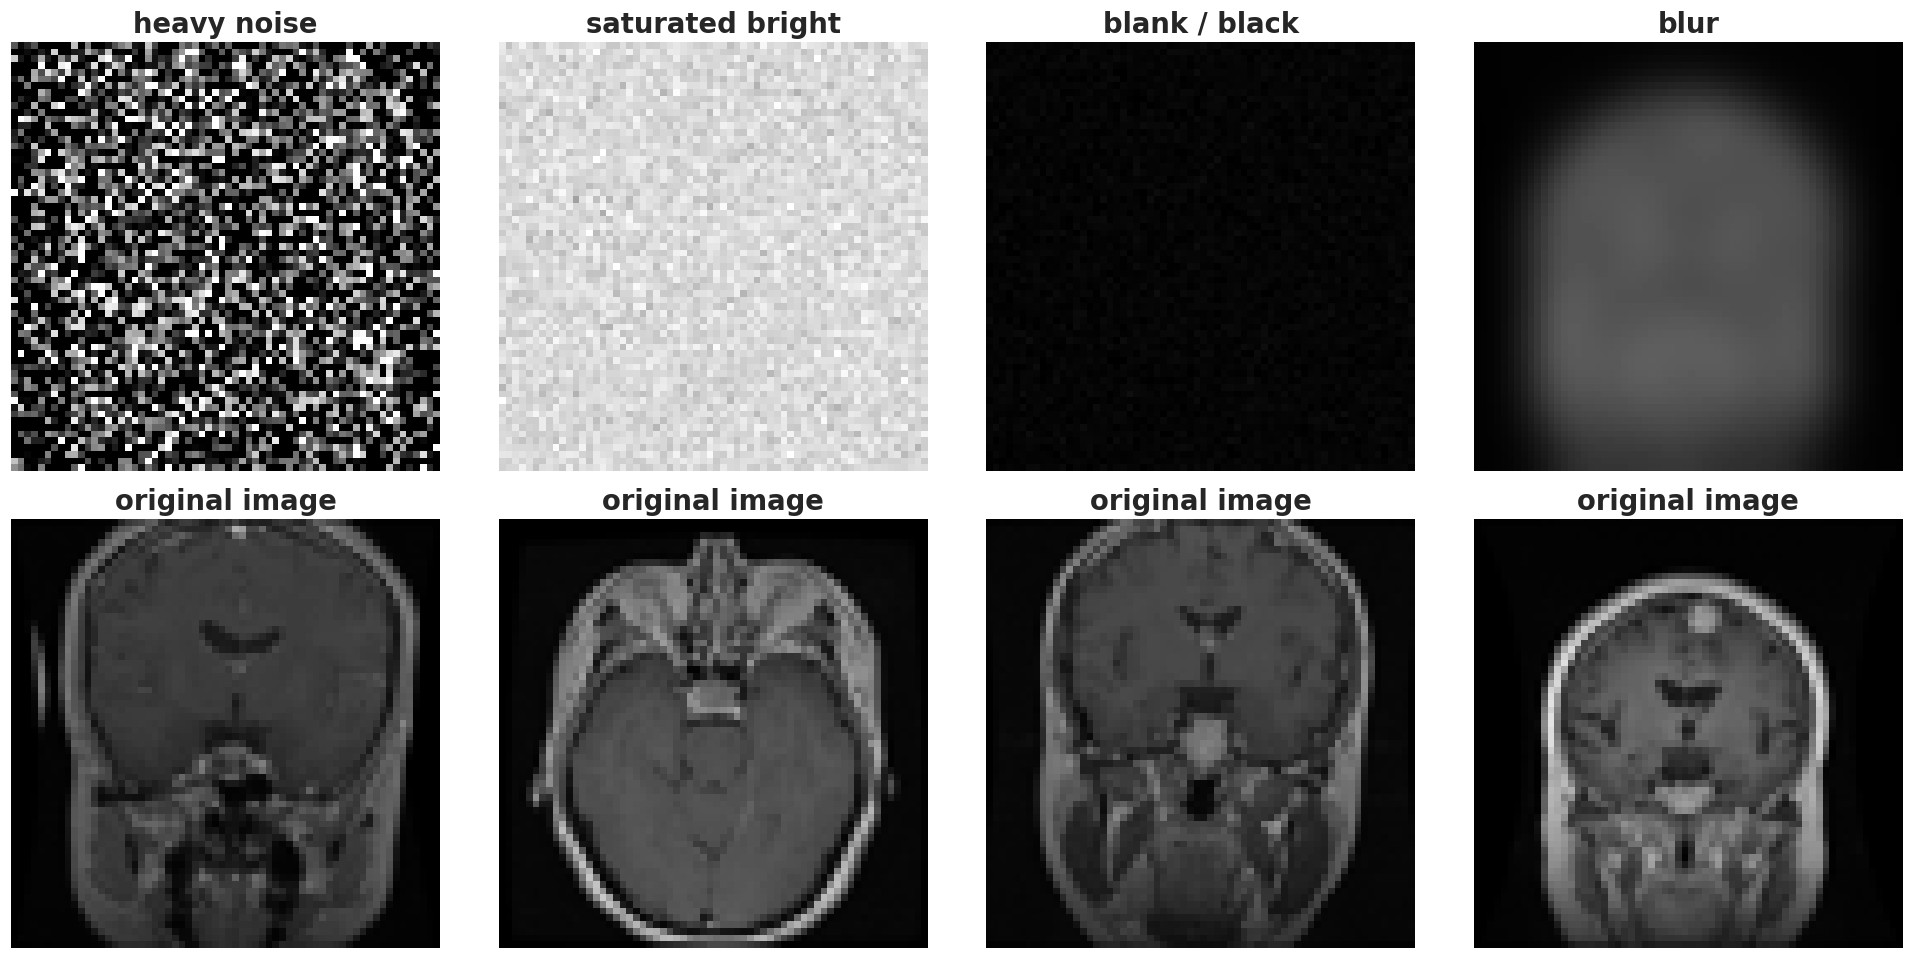


Figure 7: The four kinds of injected anomalies (top) and the real image each was made from (bottom).


In [13]:
KINDS = ["heavy noise", "saturated bright", "blank / black", "blur"]
k_out = max(4, int(round(OUT_FRAC * n))); src = rng.choice(n, k_out, replace=False)
bad, kind = [], []
for j, i in enumerate(src):
    im = X[i].reshape(IMG_SIZE, IMG_SIZE); kd = KINDS[j % 4]
    if kd == "heavy noise":        out = np.clip(im + rng.normal(0, .5, im.shape), 0, 1)
    elif kd == "saturated bright": out = np.clip(.85 + rng.normal(0, .05, im.shape), 0, 1)
    elif kd == "blank / black":    out = np.clip(rng.normal(.02, .01, im.shape), 0, 1)
    else:                          out = gaussian_filter(im, 4)
    bad.append(out.ravel().astype(np.float32)); kind.append(kd)
Xall = np.vstack([X, np.array(bad)]); yall = np.r_[y, y[src]]
is_out = np.r_[np.zeros(n, bool), np.ones(k_out, bool)]; kind = np.r_[np.array([""] * n), np.array(kind)]

def img_features(v):
    im = v.reshape(IMG_SIZE, IMG_SIZE); h = np.histogram(im, bins=32, range=(0, 1))[0] / im.size; gy, gx = np.gradient(im)
    return [im.mean(), im.std(), stats.skew(im.ravel()), stats.kurtosis(im.ravel()), -(h[h > 0] * np.log2(h[h > 0])).sum(), np.hypot(gx, gy).mean(), (im > .1).mean()]
FEATS = ["mean", "std", "skew", "kurtosis", "entropy", "edge_density", "frac_nonblack"]
F = pd.DataFrame([img_features(v) for v in Xall], columns=FEATS)
Fs = StandardScaler().fit_transform(F)
Xall_s = StandardScaler().fit_transform(Xall); Zc = PCA(2, random_state=SEED).fit_transform(Xall_s)        # PCA view of the pixels
print(f"{n} original images + {is_out.sum()} injected anomalies = {len(Xall)} images")

fig, ax = plt.subplots(2, 4, figsize=(18, 9))
for j, kd in enumerate(KINDS):
    a = ax[0, j]; i0 = np.where(kind == kd)[0][0]; a.imshow(Xall[i0].reshape(IMG_SIZE, IMG_SIZE), cmap="gray", vmin=0, vmax=1); a.set_title(kd); a.axis("off")
    a = ax[1, j]; a.imshow(X[src[list(kind[n:]).index(kd)]].reshape(IMG_SIZE, IMG_SIZE), cmap="gray", vmin=0, vmax=1); a.set_title("original image"); a.axis("off")
plt.tight_layout(); plt.show()
caption("Figure 7: The four kinds of injected anomalies (top) and the real image each was made from (bottom).")

**What you should see:** noise, saturated and blank images look obviously wrong. The blurred image, however, looks like a soft, low-detail scan, so it is the hard anomaly: the 7 summary numbers may not separate it from a genuine blurry or faint scan. 50 anomalies (1%) are added to the 5,000 real images.

## Step 6. Detect with the Z-score rule
Rule: **flag an image if ANY of its 7 features has |z| > threshold** (default 3). Rule of thumb: for bell-shaped data only about 0.3% of values exceed 3.

**How to read it:** in the histogram, anything to the right of the dashed line gets flagged. In the PCA view, red crosses are flagged images and black rings are the truly injected anomalies.

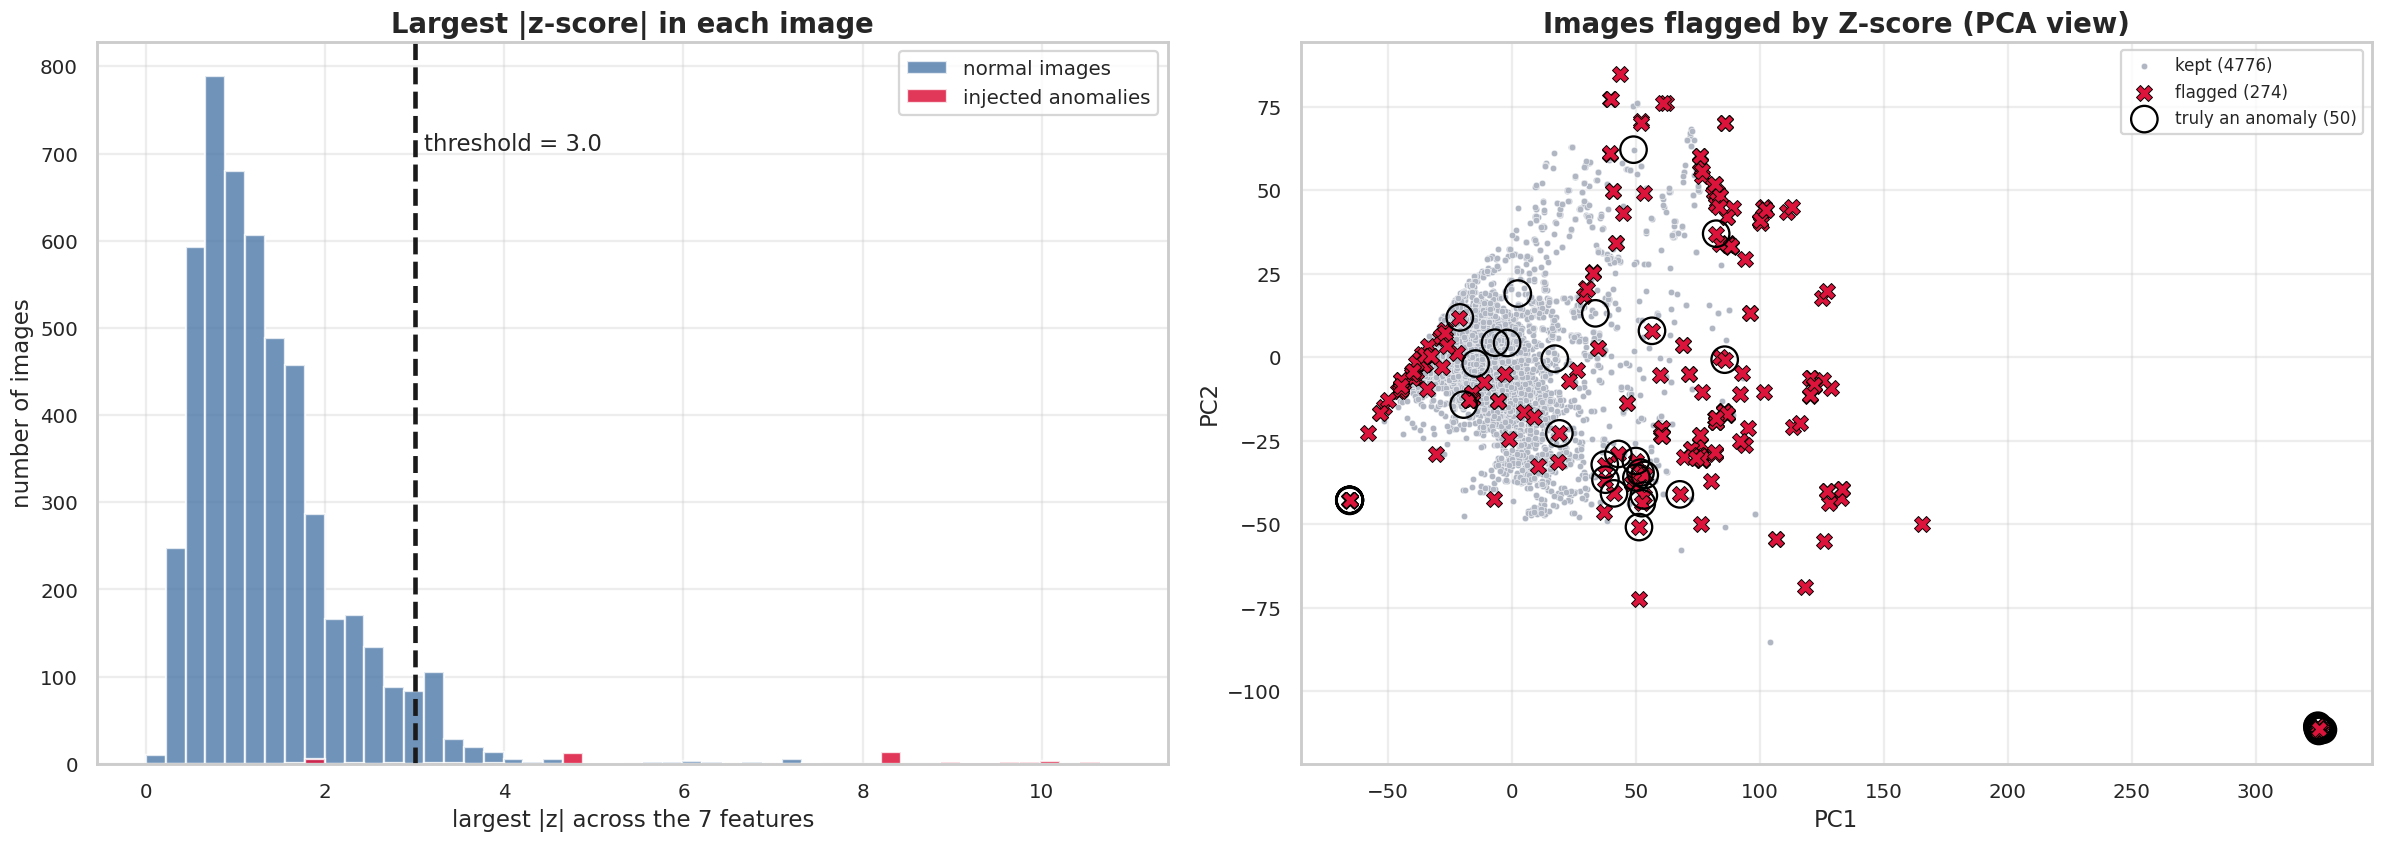


Figure 8: Z-score rule: histogram of the largest |z| per image (left) and flagged images on the PCA projection (right).


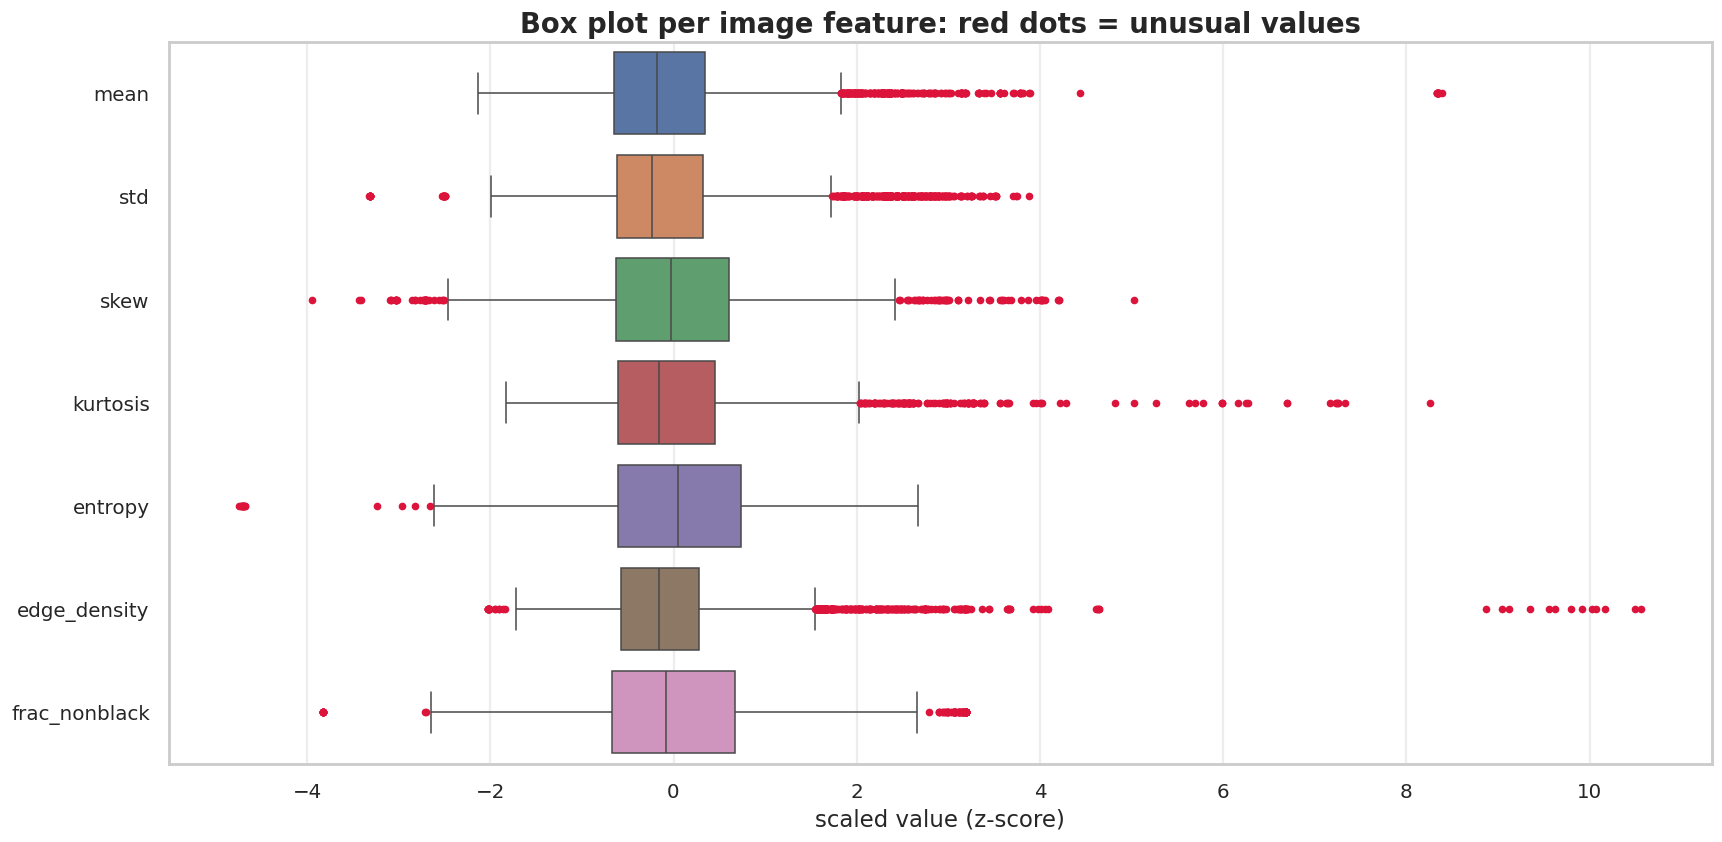

skewness of each feature: {'mean': 2.36, 'std': 1.15, 'skew': 0.25, 'kurtosis': 1.75, 'entropy': -0.45, 'edge_density': 3.2, 'frac_nonblack': 0.36}
images with |z|>3 per feature: {'mean': np.int64(61), 'std': np.int64(50), 'skew': np.int64(41), 'kurtosis': np.int64(67), 'entropy': np.int64(13), 'edge_density': np.int64(59), 'frac_nonblack': np.int64(90)}

Figure 9: Box plot of the 7 standardised image features; long one-sided tails mean skewed data.


In [14]:
def scatter_flag(ax, Z, flagged, title, truth=None, xl="", yl=""):
    ax.scatter(Z[~flagged, 0], Z[~flagged, 1], s=18, c="#b0b7c3", edgecolor="white", linewidth=.3, label=f"kept ({(~flagged).sum()})")
    ax.scatter(Z[flagged, 0], Z[flagged, 1], s=110, c="crimson", marker="X", edgecolor="black", linewidth=.6, label=f"flagged ({flagged.sum()})")
    if truth is not None: ax.scatter(Z[truth, 0], Z[truth, 1], s=300, facecolors="none", edgecolors="black", linewidth=1.5, label=f"truly an anomaly ({truth.sum()})")
    ax.set_title(title); ax.set_xlabel(xl); ax.set_ylabel(yl); ax.legend(loc="upper right", fontsize=11)

Z_abs = np.abs((F - F.mean()) / F.std(ddof=0)).values
zmax = Z_abs.max(axis=1); flag_z = zmax > Z_THRESH
fig, ax = plt.subplots(1, 2, figsize=(22, 8))
bins = np.linspace(0, zmax.max() + .3, 50)
ax[0].hist(zmax[~is_out], bins=bins, alpha=.8, color="#4c78a8", label="normal images"); ax[0].hist(zmax[is_out], bins=bins, alpha=.85, color="crimson", label="injected anomalies")
ax[0].axvline(Z_THRESH, c="k", ls="--", lw=3); ax[0].text(Z_THRESH + .1, ax[0].get_ylim()[1] * .85, f"threshold = {Z_THRESH}", fontsize=15)
ax[0].set(title="Largest |z-score| in each image", xlabel="largest |z| across the 7 features", ylabel="number of images"); ax[0].legend()
scatter_flag(ax[1], Zc, flag_z, "Images flagged by Z-score (PCA view)", truth=is_out, xl="PC1", yl="PC2")
plt.tight_layout(); plt.show()
caption("Figure 8: Z-score rule: histogram of the largest |z| per image (left) and flagged images on the PCA projection (right).")

show_f = pd.DataFrame(Fs, columns=FEATS)
plt.figure(figsize=(16, 8)); sns.boxplot(data=show_f, orient="h", fliersize=4, flierprops=dict(markerfacecolor="crimson", markeredgecolor="crimson"))
plt.title("Box plot per image feature: red dots = unusual values"); plt.xlabel("scaled value (z-score)"); plt.tight_layout(); plt.show()
sk = F.skew().round(2); print("skewness of each feature:", sk.to_dict())
print("images with |z|>3 per feature:", dict(zip(FEATS, (Z_abs > Z_THRESH).sum(0))))
caption("Figure 9: Box plot of the 7 standardised image features; long one-sided tails mean skewed data.")

the Z-score rule flags **265** images and catches **41 of the 50** injected anomalies (red bars right of the line), but it also flags **224 real images** (blue bars right of the line = false alarms). The reason is in the box plot: the features are strongly right-skewed (skewness: edge density 3.39, mean 2.37, kurtosis 1.90), so ordinary bright or sharp scans lie far out in the long tail and exceed |z| > 3. In the PCA view many red crosses sit among real images.

## Step 7. Detect with Isolation Forest
Idea: pick a random feature, pick a random split value, repeat. A weird image ends up alone after only a few splits, a normal one needs many. **Higher score = more suspicious.** Unlike Z-score, this looks at all 7 features together.

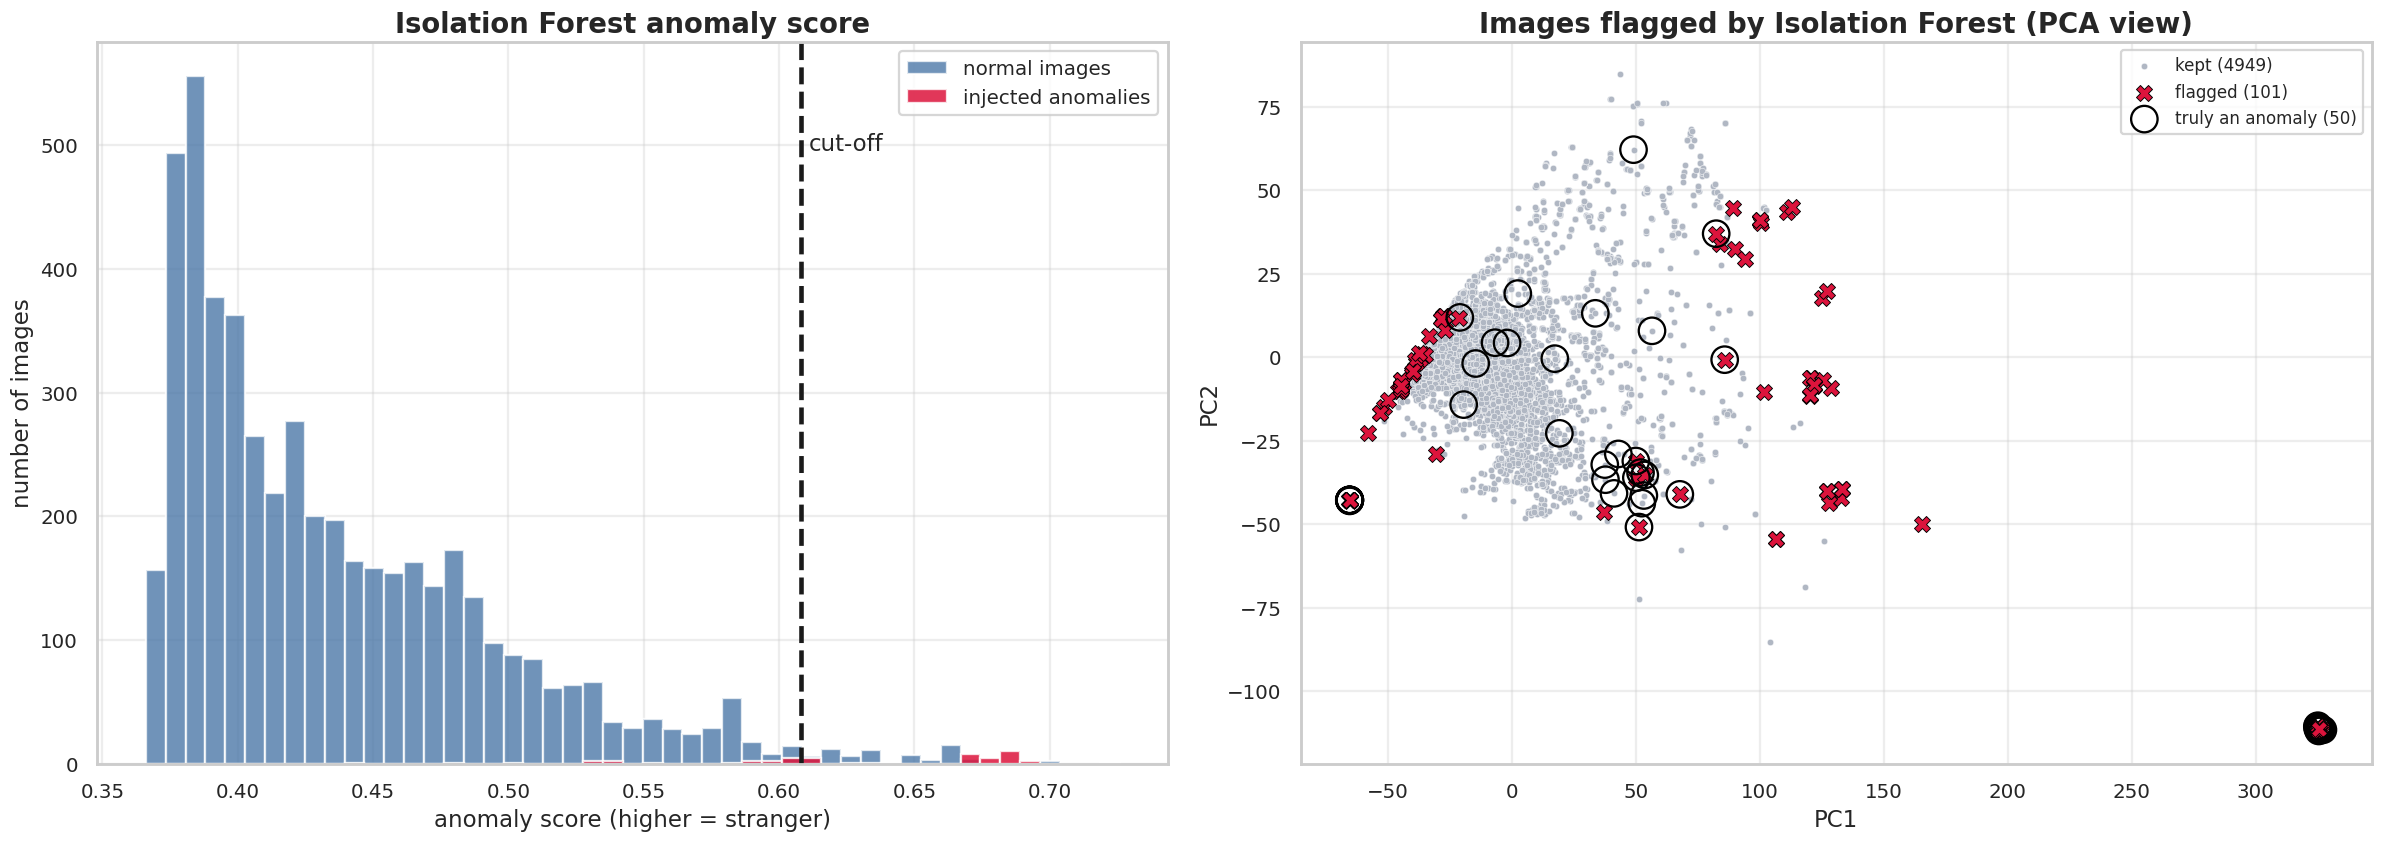


Figure 10: Isolation Forest: score histogram (left) and flagged images on the PCA projection (right).


In [15]:
iso = IsolationForest(n_estimators=300, contamination=IF_CONTAM, random_state=SEED).fit(Fs)
score = -iso.score_samples(Fs); flag_if = iso.predict(Fs) == -1
fig, ax = plt.subplots(1, 2, figsize=(22, 8))
bins = np.linspace(score.min(), score.max(), 50)
ax[0].hist(score[~is_out], bins=bins, alpha=.8, color="#4c78a8", label="normal images"); ax[0].hist(score[is_out], bins=bins, alpha=.85, color="crimson", label="injected anomalies")
ax[0].axvline(-iso.offset_, c="k", ls="--", lw=3); ax[0].text(-iso.offset_ + .003, ax[0].get_ylim()[1] * .85, "cut-off", fontsize=15)
ax[0].set(title="Isolation Forest anomaly score", xlabel="anomaly score (higher = stranger)", ylabel="number of images"); ax[0].legend()
scatter_flag(ax[1], Zc, flag_if, "Images flagged by Isolation Forest (PCA view)", truth=is_out, xl="PC1", yl="PC2")
plt.tight_layout(); plt.show()
caption("Figure 10: Isolation Forest: score histogram (left) and flagged images on the PCA projection (right).")

red bars (anomalies) are pushed to the right of the cut-off. Isolation Forest flags **101** images (the number is set by `contamination = 0.02`, not by the data), catches **35 of 50** anomalies, and wrongly flags **66** real images, far fewer false alarms than the Z-score rule, but it also misses more anomalies (15 vs 9).

## Step 8. Overlap and which method is better? (Task 7)
- **Overlap:** how many images do the two methods flag *both*?
- **Precision:** of the images we flagged, how many were really anomalies?
- **Recall:** of the real anomalies, how many did we flag?
- **F1:** one number mixing both (higher is better).
- **TP** = caught anomalies, **FP** = good images wrongly flagged, **FN** = missed anomalies.

IsolationForest flagged  False  True   All
Z-score flagged                           
False                     4767     9  4776
True                       182    92   274
All                       4949   101  5050

Z-score flags 274 | Isolation Forest flags 101 | overlap 92 | only Z-score 182 | only IsoForest 9 | Jaccard = 0.325

Table 5: Overlap of the two flag sets.


,flagged,TP,FP,FN,precision,recall,F1
method,,,,,,,
Z-score,274,41,233,9,0.150,0.82,0.253
IsolationForest,101,32,69,18,0.317,0.64,0.424
Both (AND),92,32,60,18,0.348,0.64,0.451
Either (OR),283,41,242,9,0.145,0.82,0.246



Table 6: Detection quality of each rule against the 50 injected anomalies.


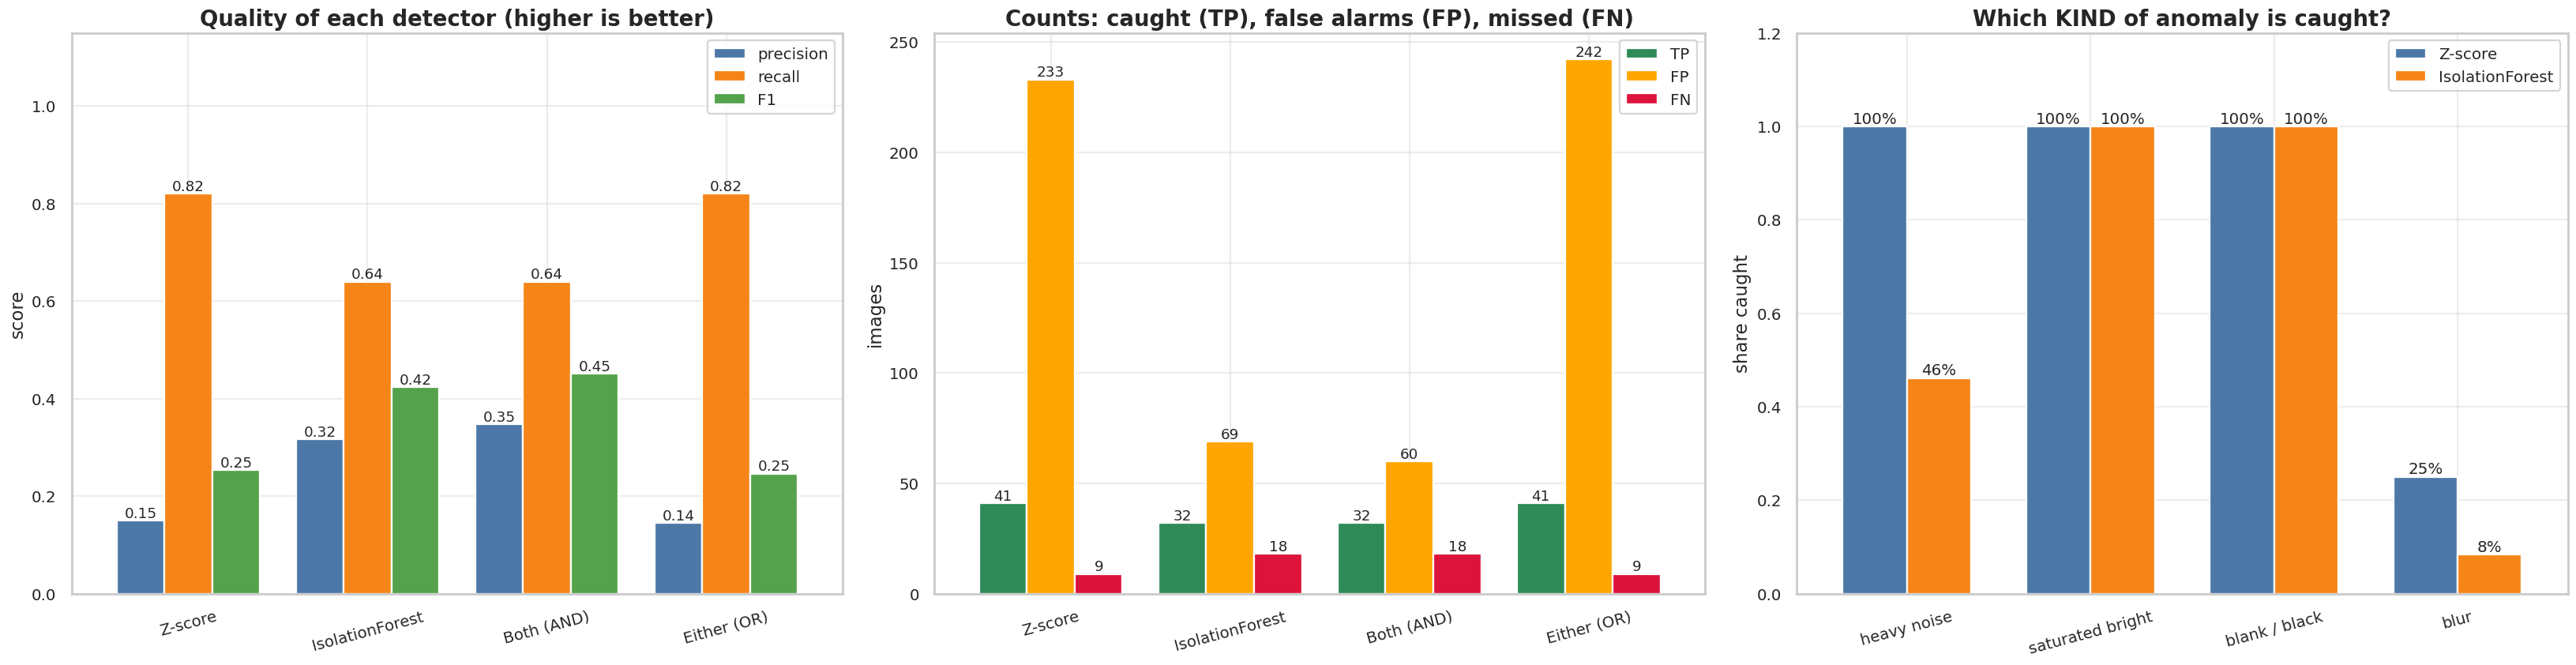


Figure 11: Precision/recall/F1 (left), TP/FP/FN counts (middle) and share of each anomaly kind that is caught (right).


In [16]:
print(pd.crosstab(flag_z, flag_if, rownames=["Z-score flagged"], colnames=["IsolationForest flagged"], margins=True))
both = int((flag_z & flag_if).sum()); union = int((flag_z | flag_if).sum())
print(f"\nZ-score flags {flag_z.sum()} | Isolation Forest flags {flag_if.sum()} | overlap {both} | only Z-score {int((flag_z & ~flag_if).sum())} | only IsoForest {int((~flag_z & flag_if).sum())} | Jaccard = {both/union:.3f}")
caption("Table 5: Overlap of the two flag sets.")

def report(name, flag):
    return dict(method=name, flagged=int(flag.sum()), TP=int((flag & is_out).sum()), FP=int((flag & ~is_out).sum()), FN=int((~flag & is_out).sum()),
                precision=precision_score(is_out, flag, zero_division=0), recall=recall_score(is_out, flag), F1=f1_score(is_out, flag, zero_division=0))
flag_both, flag_union = flag_z & flag_if, flag_z | flag_if
cmp = pd.DataFrame([report("Z-score", flag_z), report("IsolationForest", flag_if), report("Both (AND)", flag_both), report("Either (OR)", flag_union)]).set_index("method")
display(cmp.round(3)); caption("Table 6: Detection quality of each rule against the 50 injected anomalies.")

fig, ax = plt.subplots(1, 3, figsize=(30, 8))
cmp[["precision", "recall", "F1"]].plot.bar(ax=ax[0], rot=15, width=.8, color=["#4c78a8", "#f58518", "#54a24b"])
for c in ax[0].containers: ax[0].bar_label(c, fmt="%.2f", fontsize=12)
ax[0].set(title="Quality of each detector (higher is better)", ylim=(0, 1.15), xlabel="", ylabel="score")
cmp[["TP", "FP", "FN"]].plot.bar(ax=ax[1], rot=15, width=.8, color=["seagreen", "orange", "crimson"])
for c in ax[1].containers: ax[1].bar_label(c, fontsize=12)
ax[1].set(title="Counts: caught (TP), false alarms (FP), missed (FN)", xlabel="", ylabel="images")
rec = pd.DataFrame({"Z-score": [flag_z[kind == k].mean() for k in KINDS], "IsolationForest": [flag_if[kind == k].mean() for k in KINDS]}, index=KINDS)
rec.plot.bar(ax=ax[2], rot=15, width=.7, color=["#4c78a8", "#f58518"])
for c in ax[2].containers: ax[2].bar_label(c, labels=[f"{v*100:.0f}%" for v in c.datavalues], fontsize=13)
ax[2].set(title="Which KIND of anomaly is caught?", ylim=(0, 1.2), ylabel="share caught")
plt.tight_layout(); plt.show()
caption("Figure 11: Precision/recall/F1 (left), TP/FP/FN counts (middle) and share of each anomaly kind that is caught (right).")


- **Overlap:** both methods flag **92** images; 173 are flagged only by Z-score and 9 only by Isolation Forest (Jaccard = 0.336). Nearly everything Isolation Forest flags is also flagged by the Z-score rule, but the Z-score rule adds many more.
- **Quality:** Z-score has high recall (0.82) but low precision (0.155, F1 0.26). Isolation Forest has recall 0.70 and precision 0.35 (F1 0.46). *Both (AND)* gives the best F1 (0.49, precision 0.38). *Either (OR)* is no better than Z-score alone.
- **Kinds:** heavy noise is caught 100% by Z-score and 69% by Isolation Forest; saturated-bright and blank images are caught 100% by both; **blur is caught by only 25% (Z-score) and 8% (Isolation Forest)**. Z-score is good at one-feature extremes; Isolation Forest is more selective but it is not better at the hard blur case here.

## Step 9. PCA features vs original features for a classifier (Task 8)
training the **same classifier (RBF SVM)** on (a) all 4,096 standardised pixels and (b) the PCA components that keep 95% of the variance. PCA is fitted on the **training split only**, so the test images never influence the reduction.

,n_features,accuracy,macro_F1,train_time_s,pca_fit_time_s
features,,,,,
Original pixels,4096,0.902,0.8968,36.4271,0.0000
PCA 95%,458,0.898,0.8927,1.7442,30.9249



Table 7: Same SVM on original and PCA-reduced features (80/20 stratified split).


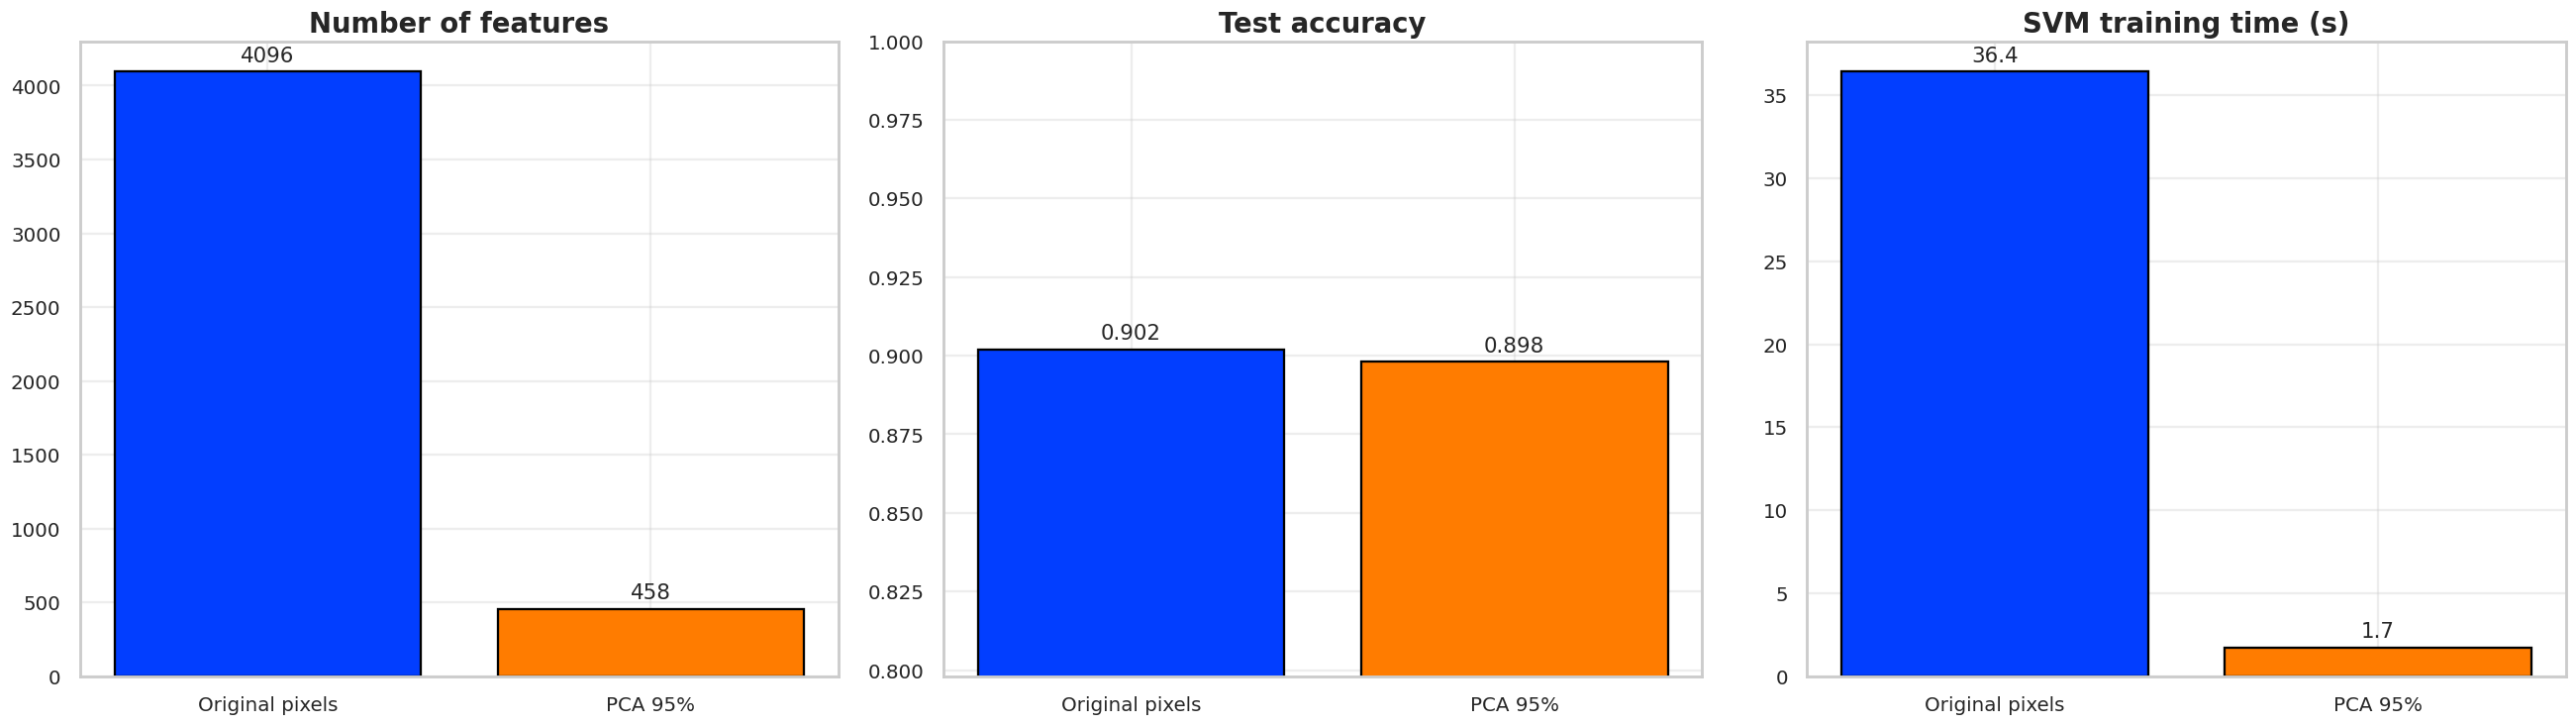


Figure 12: Features, accuracy and training time for original vs PCA features.


In [17]:
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=.2, stratify=y, random_state=SEED)
sc = StandardScaler().fit(Xtr); Xtr_s, Xte_s = sc.transform(Xtr), sc.transform(Xte)
t0 = time.time(); p95 = PCA(.95, random_state=SEED).fit(Xtr_s); Ptr, Pte = p95.transform(Xtr_s), p95.transform(Xte_s); t_pca = time.time() - t0
rows = []
for name, A, B, tp in [("Original pixels", Xtr_s, Xte_s, 0.0), ("PCA 95%", Ptr, Pte, t_pca)]:
    t0 = time.time(); clf = SVC(kernel="rbf", random_state=SEED).fit(A, ytr); tf = time.time() - t0
    pr = clf.predict(B); rows.append(dict(features=name, n_features=A.shape[1], accuracy=accuracy_score(yte, pr), macro_F1=f1_score(yte, pr, average="macro"), train_time_s=tf, pca_fit_time_s=tp))
res = pd.DataFrame(rows).set_index("features"); display(res.round(4))
caption("Table 7: Same SVM on original and PCA-reduced features (80/20 stratified split).")
fig, ax = plt.subplots(1, 3, figsize=(24, 7))
for a, col, t, fm in [(ax[0], "n_features", "Number of features", "%d"), (ax[1], "accuracy", "Test accuracy", "%.3f"), (ax[2], "train_time_s", "SVM training time (s)", "%.1f")]:
    bars = a.bar(res.index, res[col], color=PALETTE[:2], edgecolor="black"); a.bar_label(bars, fmt=fm, fontsize=14, padding=4); a.set_title(t)
ax[1].set_ylim(max(0, res.accuracy.min() - .1), 1.0)
plt.tight_layout(); plt.show()
caption("Figure 12: Features, accuracy and training time for original vs PCA features.")

 the SVM gets **0.887** accuracy on the 4,096 original pixels and **0.886** on **459** PCA components (89% fewer features), a difference of 0.001, i.e. no real loss. Training takes 14.1 s vs 1.5 s. The PCA fit itself took 14.4 s, so for a single model there is almost no net time saving; the benefit appears when the same PCA is reused for many models or new images. Note: 459 components are used here (fit on the training split) vs 477 in Step 3 (fit on all 5,000 images).